### Cell 1: imports

In [2]:
import os, heapq, itertools, time, warnings
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import gymnasium as gym
from gymnasium import spaces
from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker

### PDE, grid and exact solution
Advection–diffusion $u_t + a(x)\,u_x = \alpha u_{xx}$ on $[0,1]$, $\alpha = 0.01$, $T = 0.5$, $u(x,0) = 1 + 0.8\cos\big(2\pi(x-0.3)/1.5\big)$.
`SPEED = "ou"`: $a(x) = C(x - x_0)$, $C = -3$, $x_0 = 0.5$; the flow converges on $x_0$ (characteristics meet there). `SPEED = "constant"`: $a = 1$ (sanity case).
Exact solution $u(x,t) = \mathbb E[u_0(Y_t)]$, $Y_t$ Gaussian with mean = the foot of the characteristic and a variance from the diffusion; closed form for both speeds.
Dirichlet data at both walls from the exact solution, given like the IC. The exact solution is only used for checks and reports, never by the agent.

ou: alpha = 0.01, T = 0.5 | nx = 50, nt = 56, dx = 0.02041, dt = 9.091e-03 | r = 0.22, nu_max = 0.67, 2r + nu^2 = 0.88
check: PDE residual of the closed form, max over x: 1.2e-06


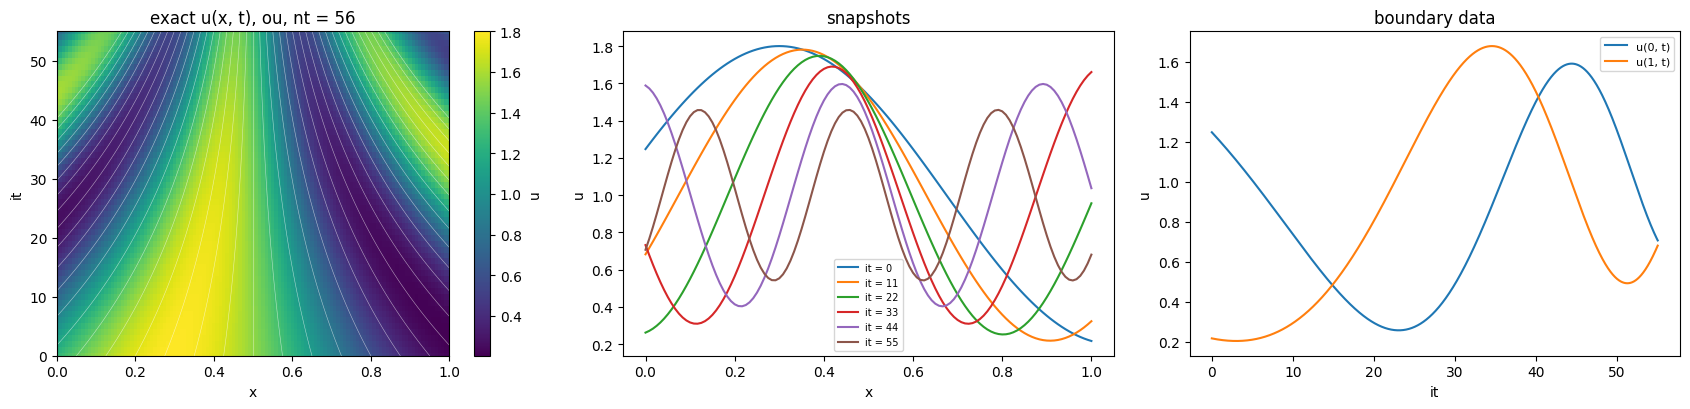

In [3]:
# ── Problem: advection-diffusion  u_t + a(x) u_x = alpha u_xx  on [0, 1], exact Dirichlet data at both walls ──
#   SPEED = "ou":       a(x) = C_OU (x - X0), C_OU < 0: the flow converges on X0 (characteristics meet there)
#   SPEED = "constant": a(x) = A_CONST (sanity case: the Green's function is a shifted, spreading Gaussian)
SPEED = "ou"
alpha, T = 0.01, 0.5
C_OU, X0, A_CONST = -3.0, 0.5, 1.0
A_PRIME = C_OU if SPEED == "ou" else 0.0                         # a'(x), constant in both cases (a'' = 0)
speed = (lambda x: C_OU * (np.asarray(x, dtype=float) - X0)) if SPEED == "ou" else (lambda x: A_CONST + 0 * np.asarray(x, dtype=float))
A_MAX = abs(C_OU) * max(X0, 1 - X0) if SPEED == "ou" else abs(A_CONST)

C_BG, A_W, L_W, X_PK = 1.0, 0.8, 1.5, 0.3                        # IC: peak at 0.3, so the structure crosses x0
K_W = 2 * np.pi / L_W
u0 = lambda x: C_BG + A_W * np.cos(K_W * (np.asarray(x, dtype=float) - X_PK))

# ── Grid: explicit LW / FD-3 stable for 2r + nu^2 <= 1 (0.9 for margin), then DT_FACTOR x that step ──
nx = 50
dx = 1.0 / (nx - 1)
_c2, _c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2)))) + 1
DT_FACTOR = 1
nt = (nt - 1) // DT_FACTOR + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution: u(x, t) = E[u0(Y_t)], Y_t Gaussian with mean m (the foot of the characteristic) and variance v ──
#   ou: m = X0 + (x - X0) e^{-C_OU t}, v = alpha (1 - e^{-2 C_OU t}) / C_OU;  constant: m = x - A_CONST t, v = 2 alpha t
#   E[cos(k (Y - X_PK))] = cos(k (m - X_PK)) e^{-k^2 v / 2}; valid on the whole line, so also outside [0, 1]
def foot(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if SPEED == "ou":
        return X0 + (x - X0) * np.exp(-C_OU * t), alpha * (1 - np.exp(-2 * C_OU * t)) / C_OU
    return x - A_CONST * t, 2 * alpha * t + 0 * x

def u_true(x, t):
    m, v = foot(x, t)
    return C_BG + A_W * np.exp(-K_W**2 * v / 2) * np.cos(K_W * (m - X_PK))

_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data u(0, t), u(1, t): exact, a cubic spline in t between levels ──
from scipy.interpolate import CubicSpline
_tb = np.linspace(0.0, T, 2001)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])
_gs = CubicSpline(_tb, _gb)
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

r_, nu_ = alpha * dt / dx**2, A_MAX * dt / dx
print(f"{SPEED}: alpha = {alpha}, T = {T} | nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e} | "
      f"r = {r_:.2f}, nu_max = {nu_:.2f}, 2r + nu^2 = {2 * r_ + nu_**2:.2f}")

# ── Check: the closed form solves the PDE ──
_x, _t, _h = np.linspace(0, 1, 11), 0.3 * T, 1e-4
_res = ((u_true(_x, _t + _h) - u_true(_x, _t - _h)) / (2 * _h) + speed(_x) * (u_true(_x + _h, _t) - u_true(_x - _h, _t)) / (2 * _h)
        - alpha * (u_true(_x + _h, _t) - 2 * u_true(_x, _t) + u_true(_x - _h, _t)) / _h**2)
print(f"check: PDE residual of the closed form, max over x: {np.abs(_res).max():.1e}")

# ── Pictures: u(x, t) with characteristics, snapshots, boundary data ──
xf  = np.linspace(0, 1, 121)
its = np.linspace(0, nt - 1, 81).round().astype(int)
Uxt = np.array([u_true(xf, it * dt) for it in its])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
im = axes[0].pcolormesh(xf, its, Uxt, shading="auto", cmap="viridis")
fig.colorbar(im, ax=axes[0], label="u")
for x_0 in np.linspace(-1, 2, 41):                                # characteristics through x_0 at t = 0
    xs = X0 + (x_0 - X0) * np.exp(C_OU * its * dt) if SPEED == "ou" else x_0 + A_CONST * its * dt
    axes[0].plot(xs, its, "w-", lw=0.4, alpha=0.6)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, nt - 1)
axes[0].set_xlabel("x"); axes[0].set_ylabel("it"); axes[0].set_title(f"exact u(x, t), {SPEED}, nt = {nt}")
for it in np.linspace(0, nt - 1, 6).round().astype(int):
    axes[1].plot(xf, u_true(xf, it * dt), label=f"it = {it}")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(fontsize=7); axes[1].set_title("snapshots")
axes[2].plot(_tb / dt, _gb[:, 0], label="u(0, t)"); axes[2].plot(_tb / dt, _gb[:, 1], label="u(1, t)")
axes[2].set_xlabel("it"); axes[2].set_ylabel("u"); axes[2].legend(fontsize=8); axes[2].set_title("boundary data")
plt.tight_layout(); plt.show()

### Taylor weights
A stencil of $n$ neighbours at offsets $(\Delta x_q, \Delta t_q)$ gets weights from 3 Taylor rows (value, $u_x$, $u_{xx}$), with $u_t = \alpha u_{xx} - a(x) u_x$ substituted, $a = a(x_p)$ (moving frame $\xi = \Delta x - a\Delta t$).
The speed changes across the stencil, so the $u_x$ row gets a term in $a'$: $\;u_q \approx u + \big[\xi - a'\Delta t(\Delta x - \tfrac12 a\Delta t)\big]u_x + \big[\tfrac12\xi^2 + \alpha\Delta t\big]u_{xx}$.
Min-norm solution; admissible if rank 3, $\mathrm{cond} \le 10^4$ and $\|w\|_1 \le 2$.

In [4]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a(x) u_x substituted ──
#   neighbour q at offset (DX, DT) from p, speed a = a(x_p), a' = A_PRIME (constant here):
#     u_q ~ u + [xi - a' DT (DX - a DT / 2)] u_x + [xi^2 / 2 + alpha DT] u_xx,   xi = DX - a DT
COND_MAX, W_MAX = 1e4, 2.0
N_SOLVES = [0]                                                        # weight systems solved so far (cost metric)
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = speed at p.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    N_SOLVES[0] += DX.shape[0]                                        # one solve per stencil
    xi = DX - a_loc * DT                                              # offset in the moving frame
    r1 = xi - A_PRIME * DT * (DX - 0.5 * a_loc * DT)                  # u_x row with the a' term
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), r1 / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

### Local error estimate (score)
The local error of a stencil at $p$ is $\delta_p=u_p-\sum_q w_q u_q$. Expanding each neighbour value in a Taylor series around $p$ (with $\sum_q w_q=1$):
$$\delta_p\approx-\sum_q w_q\,P_p(\Delta x_q,\Delta t_q),\qquad s_p=\Big|\sum_q w_q\,P_p(\Delta x_q,\Delta t_q)\Big| ,$$
with $P_p=\sum_{0<i+j\le 4}\frac{1}{i!\,j!}\,\partial_x^i\partial_t^j u\;\Delta x^i\Delta t^j$, kept up to **total degree 4** (advection-dominated: $a\Delta t\sim\Delta x$, so a $\Delta t$ counts like one $\Delta x$).
Time derivatives replaced using the PDE, one derivative at a time ($a'' = 0$, $x$-derivatives above the 4th taken as 0):
$$\partial_x^n u_t = \alpha\,\partial_x^{n+2}u - a\,\partial_x^{n+1}u - n\,a'\,\partial_x^{n}u .$$
The PDE is linear: only $u_x,\dots,u_{xxxx}$ and the speed $a(x_p)$ enter, never $u$ itself.
Check: random admissible stencils at random points, score with the **exact** derivatives vs the true local error.

300 admissible stencils, |u_x| from 0.04 to 8.62
corr(log score, log true error) = 0.98, median |score - true error| / true error = 0.03


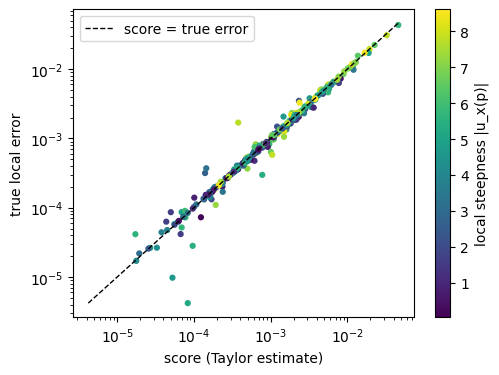

In [5]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
#   (d/dx)^n u_t = alpha u^(n+2) - a u^(n+1) - n a' u^(n)    (a'' = 0; x-derivatives above the 4th taken as 0)
#   terms up to total degree 4 in (dx, dt). u itself never enters (linear PDE), so its slot in d carries the speed a(x_p):
#   d = (a(x_p), u_x, u_xx, u_xxx, u_xxxx)  -- exactly what score_derivs passes in the map cell
from math import factorial
DEG = 4
def taylor_coeffs(d):
    """d = (a(x_p), u_x, u_xx, u_xxx, u_xxxx). Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for 0 < i + j <= DEG."""
    ap, n = d[0], np.arange(5)
    D = [np.r_[0.0, np.array(d[1:], dtype=float)]]
    for _ in range(DEG):
        P = np.r_[D[-1], 0.0, 0.0]
        D.append(alpha * P[2:] - ap * P[1:-1] - n * A_PRIME * P[:-2])
    return {(i, j): D[j][i] / (factorial(i) * factorial(j)) for j in range(DEG + 1) for i in range(5) if 0 < i + j <= DEG}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))

def x_derivs(f, x, h=2e-3):
    """(u, u_x, u_xx, u_xxx, u_xxxx) of a function f at x, by 7-point central differences."""
    v = f(x + h * np.arange(-3, 4))
    C = [[0, 0, 0, 1, 0, 0, 0], np.array([-1, 9, -45, 0, 45, -9, 1]) / 60, np.array([2, -27, 270, -490, 270, -27, 2]) / 180,
         np.array([1, -8, 13, 0, -13, 8, -1]) / 8, np.array([-1, 12, -39, 56, -39, 12, -1]) / 6]
    return tuple(np.dot(c, v) / h**k for k, c in enumerate(C))

# ── Check: score vs the true local error, random admissible stencils at random interior points (u_true ONLY here) ──
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]               # 3 levels down, |dix| <= 3
S, D, G = [], [], []
while len(S) < 300:
    p = (int(rng.integers(3, nx - 3)), int(rng.integers(3, nt)))
    nb = [cells[k] for k in rng.choice(len(cells), 5, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    ap = float(speed(p[0] * dx))
    w = solve_weights(DX, DT, ap)
    if w is None:
        continue
    d = (ap,) + x_derivs(lambda x: u_true(x, p[1] * dt), p[0] * dx)[1:]
    u_nb = np.array([U((p[0] + q[0], p[1] + q[1])) for q in nb])
    S.append(score(DX, DT, w, d)); D.append(abs(U(p) - w @ u_nb)); G.append(abs(d[1]))
S, D, G = np.array(S), np.array(D), np.array(G)
print(f"300 admissible stencils, |u_x| from {G.min():.2f} to {G.max():.2f}")
print(f"corr(log score, log true error) = {np.corrcoef(np.log(S), np.log(D))[0, 1]:.2f}, "
      f"median |score - true error| / true error = {np.median(np.abs(S - D) / D):.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(S, D, c=G, s=12, cmap="viridis")
lim = [min(S.min(), D.min()), max(S.max(), D.max())]
ax.loglog(lim, lim, 'k--', lw=1, label='score = true error')
fig.colorbar(sc, label="local steepness |u_x(p)|")
ax.set_xlabel('score (Taylor estimate)'); ax.set_ylabel('true local error'); ax.legend(); plt.show()

guess: 600 points (25 in x)
median relative error of the guess for u, u_x, u_xx, u_xxx, u_xxxx: 0.003  0.013  0.016  0.031  0.053


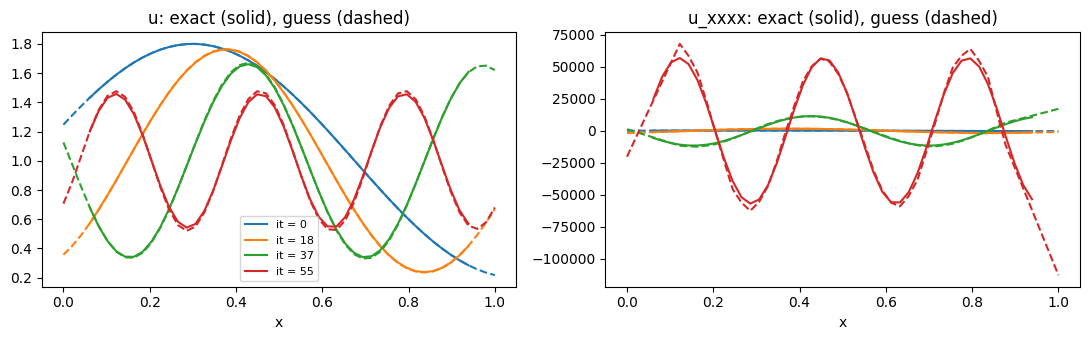

In [6]:
# ── Rough guess of u and its x-derivatives (REFERENCE only: pass 1 replaces it); the speed a(x) is known exactly ──
from scipy.interpolate import make_interp_spline
K_COARSE = 2                                                                      # 12.4: advection needed 2 (3 was too coarse)

def make_guess(K):
    """LW on a grid K times coarser, fitted with a spline in x and linear in t onto our grid.
    Returns GUESS[k, it, ix] (k-th x-derivative at grid point (ix, it)), its cost in grid points, the coarse x and dt."""
    xc  = np.linspace(0.0, 1.0, (nx - 1) // K + 1)
    hc  = xc[1] - xc[0]
    c2, c1 = (A_MAX / hc)**2, 2 * alpha / hc**2                                   # same stability rule as the main grid
    tau = T / int(np.ceil(T / ((-c1 + np.sqrt(c1**2 + 4 * c2 * 0.9)) / (2 * c2))))
    tc  = np.arange(0.0, T + tau / 2, tau)
    Uc  = [u0(xc)]
    ac  = speed(xc[1:-1])
    for j in range(1, len(tc)):
        u, ui = Uc[-1], Uc[-1][1:-1]
        r, nu = alpha * tau / hc**2, ac * tau / hc
        n = u.copy()
        n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (1 - A_PRIME * tau / 2) * (u[2:] - u[:-2])   # LW + a a' term
        n[0], n[-1] = g_left(tc[j]), g_right(tc[j])                               # boundary data
        Uc.append(n)
    Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
    for j, u in enumerate(Uc):
        sp = make_interp_spline(xc, u, k=min(5, len(xc) - 1))                     # quintic
        for k in range(5):
            Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)
    tg = np.arange(nt) * dt
    jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
    f  = ((tg - tc[jj]) / tau)[None, :, None]
    return (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1], len(xc) * len(tc), xc, tau

GUESS, G_COARSE, xc, tau = make_guess(K_COARSE)
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                     # (u, u_x, u_xx, u_xxx, u_xxxx) at q

# ── Check: guessed derivatives vs exact at 300 random points (u_true ONLY here) ──
print(f"guess: {G_COARSE} points ({len(xc)} in x)")
rng = np.random.default_rng(0)
pts = [(int(rng.integers(3, nx - 3)), int(rng.integers(1, nt))) for _ in range(300)]
ex  = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
gs  = np.array([guess_derivs(q) for q in pts])
rel = np.abs(gs - ex) / (np.abs(ex) + 1e-12)
print("median relative error of the guess for u, u_x, u_xx, u_xxx, u_xxxx: " + "  ".join(f"{v:.3f}" for v in np.median(rel, axis=0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for i, it in enumerate([0, nt // 3, 2 * nt // 3, nt - 1]):
    ex_ = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[3:-3]])
    for ax, k in zip(axes, [0, 4]):
        ax.plot(x_grid[3:-3], ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, GUESS[k, it], "--", color=f"C{i}")
axes[0].set_title("u: exact (solid), guess (dashed)"); axes[1].set_title("u_xxxx: exact (solid), guess (dashed)")
for ax in axes: ax.set_xlabel("x")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

z* = (25, 14): pass 1 = 44 points (0 without admissible weights) | LW guess up to t* = 150 points
   pass 1  median rel. error u 0.000  u_x 0.005  u_xx 0.009  u_xxx 0.047  u_xxxx 0.100
   LW      median rel. error u 0.000  u_x 0.001  u_xx 0.001  u_xxx 0.002  u_xxxx 0.004
z* = (25, 30): pass 1 = 124 points (0 without admissible weights) | LW guess up to t* = 325 points
   pass 1  median rel. error u 0.002  u_x 0.011  u_xx 0.020  u_xxx 0.090  u_xxxx 0.174
   LW      median rel. error u 0.001  u_x 0.002  u_xx 0.003  u_xxx 0.005  u_xxxx 0.020


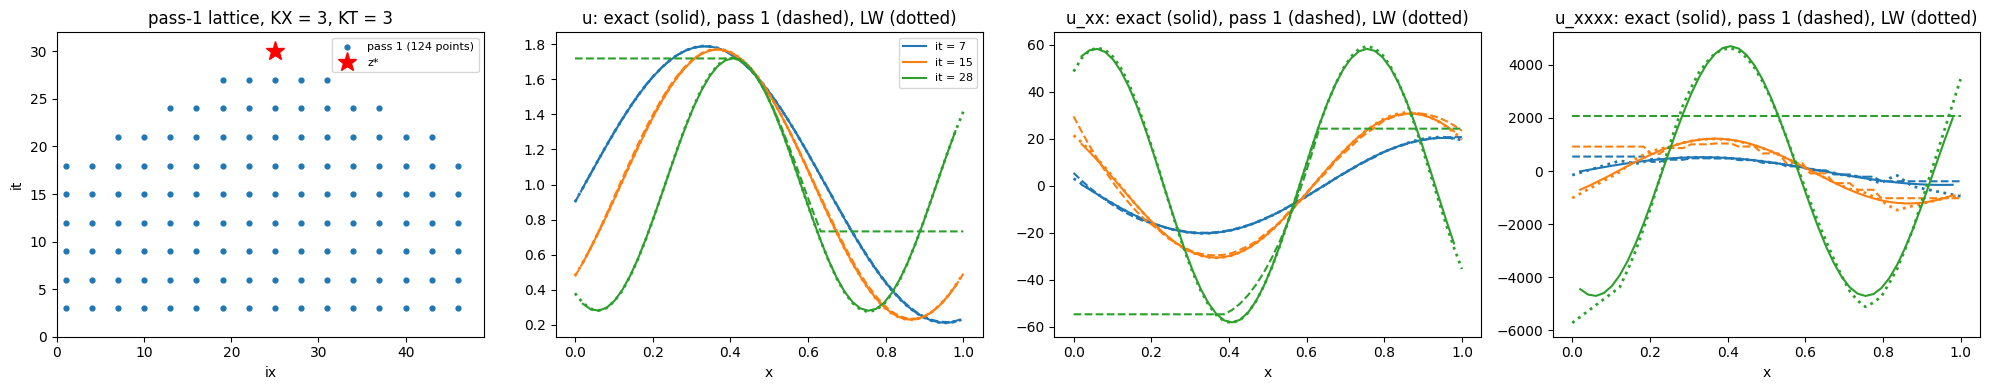

In [7]:
# ── Pass 1: a coarse UNIFORM backward map of z*, used ONLY for the guess (its values never enter u_hat(z*)) ──
#   lattice: every KX-th column and KT-th level, rooted at z*; each lattice point uses the 5 lattice points one coarse
#   level below (offsets -2..2 coarse columns), clamped onto the walls / IC (known data: exact values, like the IC)
#   values bottom-up with our Taylor weights; the speed a(x) is known, so one solve per point (linear PDE: no Picard)
from math import factorial
KX, KT = 3, 3
P1_FAIL = [0]                                                    # lattice points with no admissible weights (kept the value below)

def p1_nbs(p):
    """Pass-1 neighbours of lattice point p: the 5 lattice points one coarse level below (clamped onto walls / IC), plus
    the wall points at every fine level in between when p is near a wall (wall data is known at every time, for free)."""
    clamp = lambda q: (min(max(q[0], 0), nx - 1), max(q[1], 0))
    nbs = [clamp((p[0] + d * KX, p[1] - KT)) for d in (-2, -1, 0, 1, 2)]
    for wall in (0, nx - 1):
        if abs(p[0] - wall) <= 2 * KX:
            nbs += [(wall, p[1] - k) for k in range(1, KT) if p[1] - k > 0]
    return list(dict.fromkeys(nbs))

def pass1(z):
    """Values of z*'s coarse backward map {(ix, it): u} (lattice points only, known data excluded)."""
    known = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
    pts, todo = set(), [z]                                       # backward: the lattice points z* needs
    while todo:
        p = todo.pop()
        if p not in pts and not known(p):
            pts.add(p); todo += p1_nbs(p)
    val = {}
    get = lambda q: Ug(q) if known(q) else val[q]
    for p in sorted(pts, key=lambda p: p[1]):                    # forward: bottom-up
        nbs = p1_nbs(p)
        v   = np.array([get(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        w = solve_weights(DX, DT, float(speed(p[0] * dx)))
        if w is None:                                            # not admissible: keep the value right below
            P1_FAIL[0] += 1
            val[p] = get((p[0], max(p[1] - KT, 0)))
        else:
            val[p] = w @ v
    return val

def guess_pass1(z):
    """GUESS[k, it, ix] (k-th x-derivative) for it <= it*, and pass 1's point count.
    On each lattice level below z*: a local quartic in x (least squares through the 7 nearest lattice points, x clamped
    to the level's end points); linear in t between levels; levels above the top lattice level hold its guess."""
    val = pass1(z)
    rows = {0: (np.arange(nx) * dx, u0(np.arange(nx) * dx))}     # the IC level: known everywhere
    for it in {q[1] for q in val if q[1] < z[1]}:
        qs = sorted(q for q in val if q[1] == it)
        qs = [(0, it)] * (qs[0][0] <= 2 * KX) + qs + [(nx - 1, it)] * (qs[-1][0] >= nx - 1 - 2 * KX)   # walls the level reaches
        rows[it] = (np.array([q[0] for q in qs]) * dx, np.array([Ug(q) if q[0] in (0, nx - 1) else val[q] for q in qs]))
    D = {}
    for it, (xs, us) in rows.items():
        D[it] = np.zeros((5, nx))
        for ix in range(nx):
            x    = min(max(ix * dx, xs[0]), xs[-1])
            near = np.argsort(np.abs(xs - x))[:7]
            c    = np.polynomial.polynomial.polyfit(xs[near] - x, us[near], min(4, len(near) - 1))   # c[k] = u^(k)(x) / k!
            D[it][:len(c), ix] = c * [factorial(k) for k in range(len(c))]
    L = sorted(D)
    G = np.zeros((5, z[1] + 1, nx))
    for it in range(z[1] + 1):
        if it >= L[-1]:
            G[:, it] = D[L[-1]]
        else:
            lo = max(l for l in L if l <= it); hi = min(l for l in L if l > it)
            f  = (it - lo) / (hi - lo)
            G[:, it] = (1 - f) * D[lo] + f * D[hi]
    return G, len(val)

# ── Check: pass-1 guess vs the LW guess (GUESS, cell above) inside z*'s cone (u_true ONLY here) ──
#   check queries at the same fractions of T as Burgers' (25, 37) and (25, 75) of nt = 138
Z_CHECK = [(25, (nt - 1) * 37 // 137), (25, (nt - 1) * 75 // 137)]
rng = np.random.default_rng(0)
NAMES = ("u", "u_x", "u_xx", "u_xxx", "u_xxxx")
P1 = {}
for z in Z_CHECK:
    P1_FAIL[0] = 0
    G1, n1 = guess_pass1(z)
    P1[z] = G1
    cone = [(ix, it) for it in range(1, z[1]) for ix in range(max(1, z[0] - (z[1] - it)), min(nx - 1, z[0] + z[1] - it + 1))]
    pts  = [cone[i] for i in rng.choice(len(cone), min(300, len(cone)), replace=False)]
    ex   = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
    rel  = lambda Gs: np.median(np.abs(np.array([Gs[:, q[1], q[0]] for q in pts]) - ex) / (np.abs(ex) + 1e-12), axis=0)
    print(f"z* = {z}: pass 1 = {n1} points ({P1_FAIL[0]} without admissible weights) | "
          f"LW guess up to t* = {len(xc) * (int(z[1] * dt / tau) + 1)} points")
    for name, Gs in [("pass 1", G1), ("LW", GUESS)]:
        print(f"   {name:7s} median rel. error " + "  ".join(f"{n} {v:.3f}" for n, v in zip(NAMES, rel(Gs))))

# ── Pictures: pass-1 lattice of the larger query; exact vs pass 1 vs LW for u, u_xx, u_xxxx on three levels ──
z = Z_CHECK[-1]
val = pass1(z)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].scatter([q[0] for q in val], [q[1] for q in val], s=12, c="tab:blue", label=f"pass 1 ({len(val)} points)")
axes[0].plot(*z, "r*", ms=14, label="z*"); axes[0].set_xlim(0, nx - 1); axes[0].set_ylim(0, z[1] + 2)
axes[0].set_xlabel("ix"); axes[0].set_ylabel("it"); axes[0].legend(fontsize=8); axes[0].set_title(f"pass-1 lattice, KX = {KX}, KT = {KT}")
for i, it in enumerate([z[1] // 4, z[1] // 2, z[1] - 2]):
    ex_ = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[1:-1]])
    for ax, k in zip(axes[1:], [0, 2, 4]):
        ax.plot(x_grid[1:-1], ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, P1[z][k, it], "--", color=f"C{i}")
        ax.plot(x_grid, GUESS[k, it], ":", color=f"C{i}", lw=2)
for ax, k in zip(axes[1:], [0, 2, 4]):
    ax.set_title(f"{NAMES[k]}: exact (solid), pass 1 (dashed), LW (dotted)"); ax.set_xlabel("x")
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()

In [8]:
# ── Diagnostic: pass-1 lattice points near the left wall (larger check query) -- admissible? value vs exact ──
z = Z_CHECK[-1]
P1_FAIL[0] = 0
val = pass1(z)
clamp  = lambda q: (min(max(q[0], 0), nx - 1), max(q[1], 0))
nbs_of = lambda p: list(dict.fromkeys(clamp((p[0] + d * KX, p[1] - KT)) for d in (-2, -1, 0, 1, 2)))
print(f"z* = {z}: {len(val)} lattice points, {P1_FAIL[0]} without admissible weights")
print(f"{'ix':>3s} {'it':>3s} {'speed':>6s} {'n_nb':>4s} {'adm':>4s} {'|w|_1':>6s} {'value':>8s} {'exact':>8s} {'error':>9s}")
for p in sorted((q for q in val if q[0] <= 13), key=lambda q: (q[1], q[0])):
    nbs = nbs_of(p)
    DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
    w = solve_weights(DX, DT, float(speed(p[0] * dx)))
    print(f"{p[0]:3d} {p[1]:3d} {float(speed(p[0] * dx)):6.2f} {len(nbs):4d} {str(w is not None):>4s} "
          f"{(np.abs(w).sum() if w is not None else np.nan):6.2f} {val[p]:8.4f} {Ug(p):8.4f} {val[p] - Ug(p):9.2e}")

z* = (25, 30): 124 lattice points, 0 without admissible weights
 ix  it  speed n_nb  adm  |w|_1    value    exact     error
  1   3   1.44    4 False    nan   1.1792   1.1802 -9.54e-04
  4   3   1.26    5 True   1.22   1.3881   1.3862  1.93e-03
  7   3   1.07    5 True   1.26   1.5644   1.5625  1.83e-03
 10   3   0.89    5 True   1.25   1.6966   1.6956  1.08e-03
 13   3   0.70    5 True   1.23   1.7755   1.7750  4.34e-04
  1   6   1.44    4 False    nan   1.0321   1.0336 -1.54e-03
  4   6   1.26    5 True   1.22   1.2707   1.2672  3.53e-03
  7   6   1.07    5 True   1.26   1.4808   1.4765  4.28e-03
 10   6   0.89    5 True   1.25   1.6457   1.6428  2.96e-03
 13   6   0.70    5 True   1.23   1.7521   1.7508  1.33e-03
  1   9   1.44    4 False    nan   0.8734   0.8755 -2.10e-03
  4   9   1.26    5 True   1.22   1.1371   1.1317  5.39e-03
  7   9   1.07    5 True   1.26   1.3813   1.3740  7.34e-03
 10   9   0.89    5 True   1.25   1.5821   1.5764  5.73e-03
 13   9   0.70    5 True   1.23  

### Backward map, influence β, forward pass
**Map.** Start at $z^*$ and give it a stencil; every neighbour that is not known data (IC or wall) becomes a pending point. Points are expanded **latest $t$ first**, until every branch ends on the IC or a wall.
**Weights** use $p$'s guessed speed, rounded to 0.02 so they can be cached by (shape, speed).
**Influence.** $\beta_{z^*}=1$; when $p$ is expanded, $\beta_q \mathrel{+}= \beta_p w_q$. All users of $p$ are on higher levels, so $\beta_p$ is final when $p$ is expanded.
**Forward pass.** Values bottom-up, $\hat u_p=\sum_q w_q\hat u_q$; each point re-solves its weights with the speed of its own value (3 Picard steps), so no guessed value enters $\hat u$.
**Identity.** With $\delta_p=u_p-\sum_q w_qu_q$: $\;e(z^*)=\sum_p\beta_p\delta_p$, exact. Check with the Lax–Wendroff stencil everywhere.

In [9]:
# ── Known data: IC and walls (exact values there) ──
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = Ug
PICARD = 0                                      # forward-pass steps: 1 is within 1% of converged (cell 8 check)

# ── Speed at p for its weights: a(x) is known exactly (no guess, no rounding) ──
a_build = lambda p: float(speed(p[0] * dx))

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs with p's guessed speed; None if not admissible. Cached by (shape, speed);
    solved with the neighbours sorted, so the result does not depend on the order they were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]
    return w
 
score_derivs = lambda p: (a_build(p),) + tuple(guess_derivs(p)[1:])   # u = the rounded speed the weights use: score and weights agree

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p (u = p's rounded speed)."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, score_derivs(p))
# ── The map, built backward from z*: pending points expanded latest t first ──
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {}, "stopped": set()}
def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def pending_points(m):
    return [(ix, -it) for it, ix in m["pending"]]

def expand(m, nbs):
    """Give the next point the stencil nbs and pass its influence down. Returns (p, w)."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    for q, wq in zip(nbs, w):
        if not is_known(q):
            if q not in m["beta"]:
                m["beta"][q] = 0.0
                heapq.heappush(m["pending"], (-q[1], q[0]))
            m["beta"][q] += m["beta"][p] * wq
    return p, w

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p, or None to stop p (cell 9)."""
    m = start_map(z_star)
    while m["pending"]:
        nbs = choose(m, next_point(m))
        stop_point(m) if nbs is None else expand(m, nbs)
    return m

# ── Forward pass: values bottom-up; each point re-solves its weights with the speed of its own value (Picard) ──
def evaluate(m, picard=PICARD):
    u_hat, m["w_used"] = {}, {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in sorted(m["stencil"], key=lambda p: p[1]):
        nbs, w = m["stencil"][p]
        v = np.array([value(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w_new = solve_weights(DX, DT, float(speed(p[0] * dx)))   # (linear PDE: same speed every step)
            if w_new is None:                                   # not admissible: keep the last weights
                break
            w = w_new
        m["w_used"][p], u_hat[p] = w, w @ v
    return u_hat

# ── Reference map: one fixed 5-point stencil on the level below (LW's 3-point one is not admissible at 2 dt, r > 1/2) ──
wide = lambda m, p: list(dict.fromkeys((min(max(p[0] + d, 0), nx - 1), p[1] - 1) for d in (-2, -1, 0, 1, 2)))

# ── Check: the wide stencil everywhere; the identity must hold to all digits (map weights, picard=0) ──
for z in [(10, 20), (25, 37)]:
    m = build_map(z, wide)
    err = Ug(z) - evaluate(m, picard=0)[z]
    delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
    print(f"wide-5 map at z* = {z}: {len(m['stencil'])} points | e(z*) = {err:.6e}, sum beta*delta = "
          f"{sum(m['beta'][p] * delta[p] for p in delta):.6e} | with {PICARD} Picard steps: error {abs(Ug(z) - evaluate(m)[z]):.2e}")

wide-5 map at z* = (10, 20): 555 points | e(z*) = -2.948921e-03, sum beta*delta = -2.948921e-03 | with 0 Picard steps: error 2.95e-03
wide-5 map at z* = (25, 37): 1476 points | e(z*) = -2.676032e-03, sum beta*delta = -2.676032e-03 | with 0 Picard steps: error 2.68e-03


### Window, admissible stencils, mask, report
**Window.** Candidate neighbours of $p$: the 21 cells $|\Delta i_x|\le3$, 1–3 levels below. A cell past a wall or below $t=0$ is moved onto it (known data).
**Admissible stencils.** Every choice of 5 cells whose weights pass the test of cell 3, with $p$'s speed $a(x_p)$ (known exactly). Cached by (local situation, speed) together with each stencil's **moments** $\sum_q w_q\Delta x_q^i\Delta t_q^j$; the score at $p$ is then the moments times the Taylor coefficients at $p$.
**Mask.** The agent picks the 5 cells one at a time; a cell may be picked only if some admissible stencil contains it with the picks so far.
**Lowest score:** every point takes its lowest-score stencil (a rule, no RL). **Report:** points, true error at $z^*$, exact bound $\sum_p|\beta_p\delta_p|$ (exact solution for reporting only).

21 window cells | interior point (25, 37): 18734 admissible stencils of 20349 | first pick allowed on 21 cells
wide-5      : 1476 points, error 2.68e-03, exact bound 2.70e-03  (0 s)
lowest score: 1339 points, error 1.45e-04, exact bound 4.18e-04  (9 s)


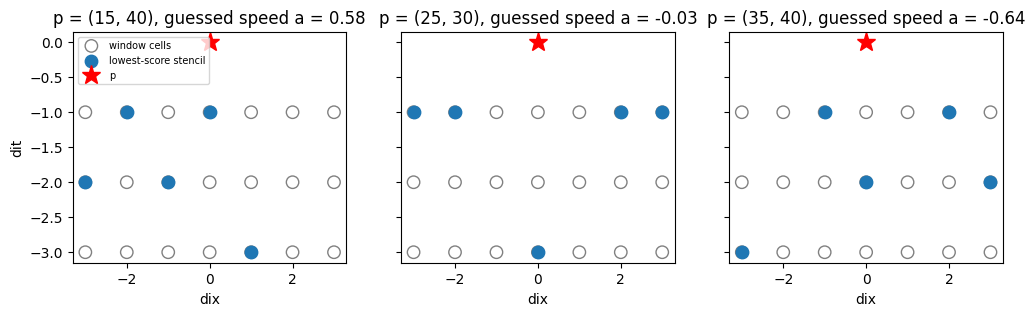

In [10]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)]
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5))                             # the (i, j) Taylor terms of the score

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p: cached by local situation and guessed speed (stencils, cell usage, moments) ──
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(score_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def pick_mask(p, picks):
    """Cell k may be picked next if some admissible stencil contains the picks so far plus k."""
    _, uses, _ = admissible(p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

def lowest_score(m, p):
    sets, _, sc = admissible(p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map, with the weights the forward pass used (u_true ONLY here) ──
def report(m, picard=PICARD):
    """Points, true error at z*, exact bound sum |beta delta| (beta recomputed with the weights actually used)."""
    z = m["z_star"]
    u_hat, W = evaluate(m, picard), m["w_used"]
    beta = {z: 1.0}
    for p in sorted(m["stencil"], key=lambda p: -p[1]):           # every user before the points it uses
        for q, wq in zip(m["stencil"][p][0], W[p]):
            if not is_known(q):
                beta[q] = beta.get(q, 0.0) + beta[p] * wq
    delta = {p: Ug(p) - W[p] @ np.array([Ug(q) for q in m["stencil"][p][0]]) for p in m["stencil"]}
    return {"points": len(m["stencil"]), "error": abs(Ug(z) - u_hat[z]),
            "bound": sum(abs(beta[p] * delta[p]) for p in delta)}

# ── Check ──
z = (25, 37)
sets, _, sc = admissible(z)
print(f"{N_CELLS} window cells | interior point {z}: {len(sets)} admissible stencils of "
      f"{len(list(itertools.combinations(range(N_CELLS), N_NB)))} | first pick allowed on {pick_mask(z, []).sum()} cells")
for name, rule in [("wide-5", wide), ("lowest score", lowest_score)]:
    t0 = time.time()
    rep = report(build_map(z, rule))
    print(f"{name:12s}: {rep['points']} points, error {rep['error']:.2e}, exact bound {rep['bound']:.2e}  ({time.time() - t0:.0f} s)")

    
# ── Picture: the lowest-score stencil at three points with different speeds ──
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, p in zip(axes, [(15, 40), (25, 30), (35, 40)]):
    sets, _, sc = admissible(p)
    best = sets[int(np.argmin(sc))]
    ax.scatter(*np.array(WINDOW).T, s=80, facecolors='none', edgecolors='gray', label='window cells')
    ax.scatter(*np.array([WINDOW[k] for k in best]).T, s=80, color='tab:blue', label='lowest-score stencil')
    ax.plot(0, 0, 'r*', ms=14, label='p')
    ax.set_title(f"p = {p}, guessed speed a = {a_build(p):.2f}"); ax.set_xlabel('dix')
axes[0].set_ylabel('dit'); axes[0].legend(fontsize=7, loc='upper left'); plt.show()

### Greedy and the cost of each rule
**Greedy**: at every point, the admissible stencil with the best one-step reward, $\;|\beta_p|s_p/\mathrm{EPS}+\lambda\,(\text{new points})/N_{\rm LW}$.
**Cost** of a map: points, and weight systems solved — for the stencil library (all candidates, once per local situation and speed, shared by every query), while building, and in the forward pass (1 Picard step per point). Cold = empty library, warm = library already filled.

In [11]:
# ── Reward units (also used by the environment) ──
EPS = 1e-3                                                        # accuracy unit
def n_lw(z):
    """Points unit: size of z*'s LW cone (one more column each side per level, walls excluded) = the LW map's
    point count at the explicit dt; counted directly because LW's 3-point stencil is not admissible at 2 dt."""
    return sum(min(nx - 2, z[0] + j) - max(1, z[0] - j) + 1 for j in range(z[1]))

def greedy_rule(lam):
    """At every point the admissible stencil with the best one-step reward (beta_p is final when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = admissible(p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

# ── Cost of each rule at z*: points, weight solves (build, forward), time; library cold or warm ──
def cost_run(z, rule, cold):
    if cold:
        _sets_cache.clear(); _w_cache.clear()
    n0, t0 = N_SOLVES[0], time.time()
    m = build_map(z, rule)
    n_build, t_build = N_SOLVES[0] - n0, time.time() - t0
    rep = report(m)                                               # the forward pass (3 Picard steps) happens here
    return rep | {"solves_build": n_build, "solves_fwd": N_SOLVES[0] - n0 - n_build, "time": t_build}

z = (25, 37)
n_lw(z)
print(f"{'rule':14s} {'library':8s} {'points':>7s} {'error':>9s} {'bound':>9s} {'solves build':>13s} {'solves fwd':>11s} {'build time':>11s}")
for name, rule in [("wide-5", wide), ("lowest score", lowest_score), ("greedy lam=1", greedy_rule(1.0))]:
    for cold in (True, False):
        r = cost_run(z, rule, cold)
        print(f"{name:14s} {'cold' if cold else 'warm':8s} {r['points']:7d} {r['error']:9.2e} {r['bound']:9.2e} "
              f"{r['solves_build']:13,d} {r['solves_fwd']:11,d} {r['time']:10.1f}s")

        # ── How many Picard steps are needed? error and exact bound vs steps, same maps (0 = the build weights) ──
for name, rule in [("wide-5", wide), ("lowest score", lowest_score), ("greedy lam=1", greedy_rule(1.0))]:
    m = build_map(z, rule)
    reps = {k: report(m, picard=k) for k in (0, 1, 2, 3, 5)}
    print(f"{name:14s} | " + "  ".join(f"{k}: err {r['error']:.2e} bnd {r['bound']:.2e}" for k, r in reps.items()))

rule           library   points     error     bound  solves build  solves fwd  build time
wide-5         cold        1476  2.68e-03  2.70e-03            48           0        0.0s
wide-5         warm        1476  2.68e-03  2.70e-03             0           0        0.0s
lowest score   cold        1339  1.45e-04  4.18e-04     1,010,929           0        9.5s
lowest score   warm        1339  1.45e-04  4.18e-04             0           0        0.2s
greedy lam=1   cold         566  2.12e-04  4.54e-04       951,257           0        8.5s
greedy lam=1   warm         566  2.12e-04  4.54e-04             0           0        0.2s
wide-5         | 0: err 2.68e-03 bnd 2.70e-03  1: err 2.68e-03 bnd 2.70e-03  2: err 2.68e-03 bnd 2.70e-03  3: err 2.68e-03 bnd 2.70e-03  5: err 2.68e-03 bnd 2.70e-03
lowest score   | 0: err 1.45e-04 bnd 4.18e-04  1: err 1.45e-04 bnd 4.18e-04  2: err 1.45e-04 bnd 4.18e-04  3: err 1.45e-04 bnd 4.18e-04  5: err 1.45e-04 bnd 4.18e-04
greedy lam=1   | 0: err 2.12e-04 bnd 4

### Stops: reuse of existing points
A **stop** gives $p$ no new stencil: its value comes from points **already in the map**, so no new points are created. Candidates are the pending map points on **lower** levels than $p$ and the known data (IC, walls below $p$), at any distance (higher points could depend on $p$: a cycle). Of the 8 nearest, the admissible 5-subset with the lowest score is the stop stencil; its weights are the usual Taylor weights and its score is the stop's cost. If no subset is admissible, $p$ cannot stop. The identity $e(z^*)=\sum_p\beta_p\delta_p$ stays exact.
Check: LW with every low-influence point stopped (identity), and greedy + stop (stop when it costs less now than the best stencil).

In [12]:
# ── Stops: p takes its value from points already in the map (no new points) ──
#   candidates: pending map points on LOWER levels than p, and known data (IC, walls below p), at any distance
#   the K_REUSE nearest; the stop stencil = their admissible 5-subset with the lowest score
K_REUSE = 8

def reuse_stencil(m, p):
    """(neighbours, weights, score) of p's best stop stencil, or None if no admissible one. Cached for the current p."""
    key = (p, len(m["stencil"]))
    if m.get("_reuse_key") != key:
        cand = [q for q in pending_points(m) if q[1] < p[1]]
        cand += [(ix, 0) for ix in range(nx)] + [(w, it) for w in (0, nx - 1) for it in range(1, p[1])]
        cand = sorted(set(cand), key=lambda q: (q[0] - p[0])**2 + (q[1] - p[1])**2)[:K_REUSE]
        sets = list(itertools.combinations(cand, N_NB))
        DX = np.array([[q[0] - p[0] for q in s] for s in sets]) * dx
        DT = np.array([[q[1] - p[1] for q in s] for s in sets]) * dt
        W, ok = solve_weights_many(DX, DT, a_build(p))
        best = None
        if ok.any():
            sc = score(DX[ok], DT[ok], W[ok], score_derivs(p))
            i = int(np.argmin(sc))
            best = (list(sets[np.flatnonzero(ok)[i]]), W[ok][i], float(sc[i]))
        m["_reuse_key"], m["_reuse"] = key, best
    return m["_reuse"]

def stop_point(m):
    """Stop the next point: it uses its stop stencil (all neighbours already exist) and passes its influence down."""
    p = next_point(m)
    nbs, w, _ = reuse_stencil(m, p)
    heapq.heappop(m["pending"])
    m["stencil"][p] = (nbs, w)
    m["stopped"].add(p)
    for q, wq in zip(nbs, w):
        if not is_known(q):
            m["beta"][q] += m["beta"][p] * wq
    return p, w

def greedy_stop_rule(lam):
    """Greedy, plus: stop p (None) when its stop costs less now than its best stencil."""
    greedy = greedy_rule(lam)
    def choose(m, p):
        nbs = greedy(m, p)
        r = None if p == m["z_star"] else reuse_stencil(m, p)
        if r is None:
            return nbs
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in m["beta"])
        cost_stencil = abs(m["beta"][p]) * point_score(p, nbs, weights(p, nbs)) / EPS + lam * n_new / n_lw(m["z_star"])
        return None if abs(m["beta"][p]) * r[2] / EPS < cost_stencil else nbs
    return choose


In [13]:
# ── From here on the guess is PASS 1 (KX x KT lattice), no LW: built once per query, made active before a map is built ──
#   every function reads the guess through guess_derivs; the active guess sits in a dict (mutated, never rebound),
#   so the training processes see the change too. (Advection: the speed is known, the guess only feeds the score/state)
KX, KT = 3, 3                                                     # from the sweep
_ACTIVE, _P1 = {"G": None}, {}
guess_derivs = lambda q: _ACTIVE["G"][:, q[1], q[0]]             # (u, u_x, u_xx, u_xxx, u_xxxx) at q

def use_guess(z):
    """Make z*'s pass-1 guess the active one. Returns pass 1's points (added to every map method's cost)."""
    if z not in _P1:
        _P1[z] = guess_pass1(z)
    _ACTIVE["G"] = _P1[z][0]
    return _P1[z][1]

_build_map = build_map
def build_map(z_star, choose):
    """Same as before, with z*'s own pass-1 guess made active first (every rule-built map goes through here)."""
    use_guess(z_star)
    return _build_map(z_star, choose)

# ── Check: greedy at the selection query on the pass-1 guess ──
n1 = use_guess((25, 30))
r = report(build_map((25, 30), greedy_rule(1.0)))
print(f"pass 1 at (25, 30): {n1} points | greedy: {r['points']} points, error {r['error']:.2e}, bound {r['bound']:.2e}")

pass 1 at (25, 30): 124 points | greedy: 407 points, error 1.60e-04, bound 4.80e-04


### Environment
**Episode.** Build one map for $z^*$. Each step the agent picks one window cell for the current point, or **STOP** (only with `stops=True`, before its first pick, never at $z^*$, only if a stop stencil exists). After 5 picks the point is expanded.
**Reward.** Accuracy per decision: $-|\beta_p|s_p/\mathrm{EPS}$ (a stencil) or $-|\beta_p|s^{\rm stop}_p/\mathrm{EPS}$ (a stop). Points cost, `points_cost`:
- `"step"`: $-\lambda\,(\text{new points})/N_{LW}$ at each stencil;
- `"terminal"`: $-\lambda\,N_{\rm total}/N_{LW}$ once at the end (same total as "step");
- `"avg_dt"`: $-\lambda\,(1-\overline{\text{depth}}/3)$ once at the end.

**Shaping** (`shaping`): every reward gets $\Phi(s')-\Phi(s)$; the extra terms add up to $-\Phi(s_0)$, a constant, so the best policy does not change.
- `"lw"`: $\Phi=-\sum_{q\ \rm pending}\big(|\beta_q|A_q/\mathrm{EPS}+\lambda N_q/N_{LW}\big)$, the LW map's cost-to-go;
- `"height"`: $\Phi=-\lambda\hat N/N_{LW}$, $\hat N=\sum_x\max(0,c(x)-1)$, $c(x)=\max_q(t_q-|x-i_q|)$: the points still to create, as the union of the pending points' backward cones.

**State**: per window cell picked / in the map / known data; $\log|\beta_p|$, position, guessed $u,u_x,u_{xx}$, points used and pending, pending influence, $\log\lambda$, whether $p$ can stop and what it would cost, mean stencil depth so far.
Check: one random episode per setting; the rewards must add up to the return formula (with shaping, differ by exactly $-\Phi(s_0)$).

In [14]:
# ── Shaping potentials (estimates only: score, beta, no u_true) ──
#   "lw":     cost-to-go of every point of the wide-5 map of z*  (A_q: estimated error of q's subtree per unit influence,
#             N_q: points of q's subtree, a point shared by several users split between them)
#   "height": points still to create = the union of the pending points' backward cones (one cell per level each side),
#             c(x) = max_q (t_q - |x - i_q|),  N_hat = sum_x max(0, c(x) - 1)
def cost_to_go(m):
    users = {}
    for p, (nbs, w) in m["stencil"].items():
        for q in set(nbs):
            users[q] = users.get(q, 0) + 1
    A, N = {}, {}
    for p in sorted(m["stencil"], key=lambda p: p[1]):            # bottom-up: the points a stencil uses come first
        nbs, w = m["stencil"][p]
        A[p], N[p] = point_score(p, nbs, w), 1.0
        for q, wq in zip(nbs, w):
            if q in A:                                            # an expanded point (not data)
                A[p] += abs(wq) * A[q]
                N[p] += N[q] / users[q]
    return A, N

_ctg_cache = {}
def lw_cost_to_go(z):
    if z not in _ctg_cache:
        _ctg_cache[z] = cost_to_go(build_map(z, wide))
    return _ctg_cache[z]

_xs = np.arange(1, nx - 1)
def cone_points(pend):
    """Points still to create below the pending points: the union of their backward cones (interior columns)."""
    if not pend:
        return 0.0
    ix, it = np.array(pend).T
    c = (it[None, :] - np.abs(_xs[:, None] - ix[None, :])).max(1)
    return float(np.maximum(0, c - 1).sum())

# ── Environment: one step = one pick, or STOP ──
#   stencil at p : -|beta_p| s_p / EPS      (- lam * new points / N_LW   if points_cost = "step")
#   stop at p    : -|beta_p| s_stop / EPS   (no new points)
#   end          : - lam * total points / N_LW             if points_cost = "terminal"  (same total as "step")
#                  - lam * (1 - mean stencil depth / K_T)   if points_cost = "avg_dt"
#   shaping      : + Phi(s') - Phi(s) on every reward; the extra terms add up to -Phi(start), a constant of the query
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
STOP    = N_CELLS                                                 # the extra action
N_OBS   = 3 * N_CELLS + 15

# ── Menu of stencil shapes (switch menu=MENU): one action = one whole stencil, instead of 5 cell picks ──
#   MENU = every shape greedy uses at the training query (tuples of window cells), most used first.
#   State adds each shape's new points (bookkeeping, no Taylor score). A point where no menu shape is admissible
#   gets its lowest-score stencil without a decision (like the forced points).
def menu_from(z, rule):
    used = {}
    def choose(m, p):
        nbs = rule(m, p)
        cells = next(c for c in admissible(p)[0] if [place(p, k) for k in c] == nbs)
        used[cells] = used.get(cells, 0) + 1
        return nbs
    build_map(z, choose)
    return sorted(used, key=used.get, reverse=True)

Z_MULTI = [(25, 30), (15, 25), (35, 25), (25, 20)]
MENU = list(dict.fromkeys(c for z in Z_MULTI for c in menu_from(z, greedy_rule(1.0))))   # every shape greedy uses at the training queries
MENU_USES = np.zeros((len(MENU), N_CELLS))                       # MENU_USES[i, k] = 1 if shape i uses window cell k
for i, c in enumerate(MENU):
    MENU_USES[i, list(c)] = 1
_menu_ok = {}
def menu_ok(p):
    """Which menu shapes are admissible at p (cached with p's admissible list)."""
    sets = admissible(p)[0]
    if id(sets) not in _menu_ok:
        have = set(sets)
        _menu_ok[id(sets)] = (sets, np.array([c in have for c in MENU]))
    return _menu_ok[id(sets)][1]
print(f"menu: {len(MENU)} shapes")

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(1.0, 1.0), cap=3.0, stops=False, shaping=None, points_cost="step", menu=None):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.stops, self.shaping, self.points_cost, self.menu = stops, shaping, points_cost, menu
        self.n_obs = N_OBS + (len(menu) if menu else 0)
        self.stop_a = len(menu) if menu else STOP                   # index of the STOP action
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(self.n_obs,), dtype=np.float32)
        self.action_space = spaces.Discrete(self.stop_a + 1)        # one window cell (or one menu shape), or STOP

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.guess_points = use_guess(self.z)                      # pass-1 guess of this query
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B, self.depths = start_map(self.z), [], 0.0, []
        self.phi0 = self.phi = self._phi()
        self.carry = self._play_forced()                          # forced points before the first decision: paid at step 1
        return self._obs(), {}

    def _phi(self):
        """Shaping potential: minus the estimated cost of finishing the pending points (0 without shaping)."""
        pend = pending_points(self.m)
        if self.shaping == "lw":
            A, N = lw_cost_to_go(self.z)
            return -sum(abs(self.m["beta"][q]) * A.get(q, 0.0) / EPS + self.lam * N.get(q, 1.0) / self.N_ref for q in pend)
        if self.shaping == "height":
            return -self.lam * cone_points(pend) / self.N_ref
        return 0.0

    def _complete(self, cells):
        """Expand the next point with these cells: its accuracy now (beta_p is final), and its new points if per step."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, w = expand(self.m, nbs)
        acc = abs(self.m["beta"][p]) * point_score(p, nbs, w)
        self.B += acc
        self.depths.append(np.mean([p[1] - q[1] for q in nbs]))
        return -acc / EPS - (self.lam * n_new / self.N_ref if self.points_cost == "step" else 0.0)

    def _stop(self):
        """Stop the next point: its value from existing points; its accuracy now, no new points."""
        p = next_point(self.m)
        acc = abs(self.m["beta"][p]) * reuse_stencil(self.m, p)[2]
        stop_point(self.m)
        self.B += acc
        return -acc / EPS

    def _play_forced(self):
        """Points with only one admissible stencil need no decision."""
        r = 0.0
        while self.m["pending"]:
            p = next_point(self.m)
            sets, _, sc = admissible(p)
            if len(sets) == 1:
                r += self._complete(sets[0])
            elif self.menu and not menu_ok(p).any():                # no menu shape fits: lowest score, no decision
                r += self._complete(sets[int(np.argmin(sc))])
            else:
                break
        return r

    def _can_stop(self, p):
        return self.stops and not self.picks and p != self.z and reuse_stencil(self.m, p) is not None

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(self.n_obs, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = pending_points(self.m)
        d      = guess_derivs(p)
        can    = self._can_stop(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam),                                # price of a point
                float(can),                                        # can p stop now?
                np.log10(abs(self.m["beta"][p]) * reuse_stencil(self.m, p)[2] / EPS + 1e-12) if can else 0.0,   # cost of stopping p now
                np.mean(self.depths) / K_T if self.depths else 0.0]   # mean stencil depth so far (levels / K_T)
        new = [MENU_USES @ (~exists & ~known) / N_NB] if self.menu else []   # each menu shape's new points (/ 5)
        return np.concatenate([picked, exists, known, glob, *new]).astype(np.float32)

    def step(self, k):
        r, self.carry = self.carry, 0.0
        if k == self.stop_a:
            r += self._stop()
        elif self.menu:
            r += self._complete(self.menu[k])
        else:
            self.picks.append(int(k))
            if len(self.picks) < len(admissible(next_point(self.m))[0][0]):    # still choosing p's stencil
                return self._obs(), r, False, False, {}
            r += self._complete(self.picks)
            self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            phi = self._phi()
            r, self.phi = r + phi - self.phi, phi
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: every point left unexpanded costs its worst stencil
        for q in pending_points(self.m):
            acc = abs(self.m["beta"][q]) * admissible(q)[2].max()
            self.B += acc
            r -= acc / EPS
        n_points = len(self.m["stencil"]) + len(self.m["pending"]) - 1          # every point but z*
        if self.points_cost == "terminal":
            r -= self.lam * n_points / self.N_ref
        elif self.points_cost == "avg_dt":
            r -= self.lam * (1 - np.mean(self.depths) / K_T)
        r -= self.phi                                              # Phi = 0 at the end
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "stops": len(self.m["stopped"]),
                "lam": self.lam, "score_ratio": self.B / EPS, "points_ratio": n_points / self.N_ref,
                "depth": float(np.mean(self.depths))}
        return np.zeros(self.n_obs, np.float32), r, True, False, info

    def action_masks(self):
        p = next_point(self.m)
        cells = menu_ok(p) if self.menu else pick_mask(p, self.picks)
        return np.r_[cells, self._can_stop(p)]                      # STOP: before the first pick, never at z*, if possible

menu: 918 shapes


### Map figure
One figure for any finished map (baselines, training snapshots, the progress video):
1. the map, coloured by influence $|\beta_p|$ on $z^*$, stopped points marked;
2. the solution at $t^*$: exact $u(x,t^*)$, the computed points of the top levels, and the predicted vs exact value at $z^*$.

The exact solution is used only in this figure.

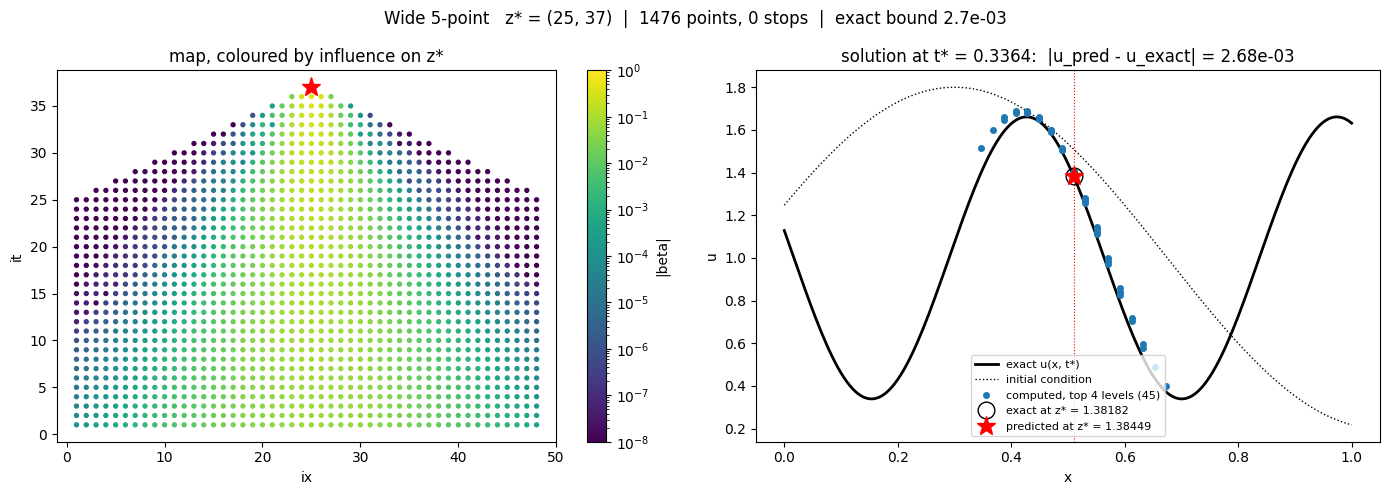

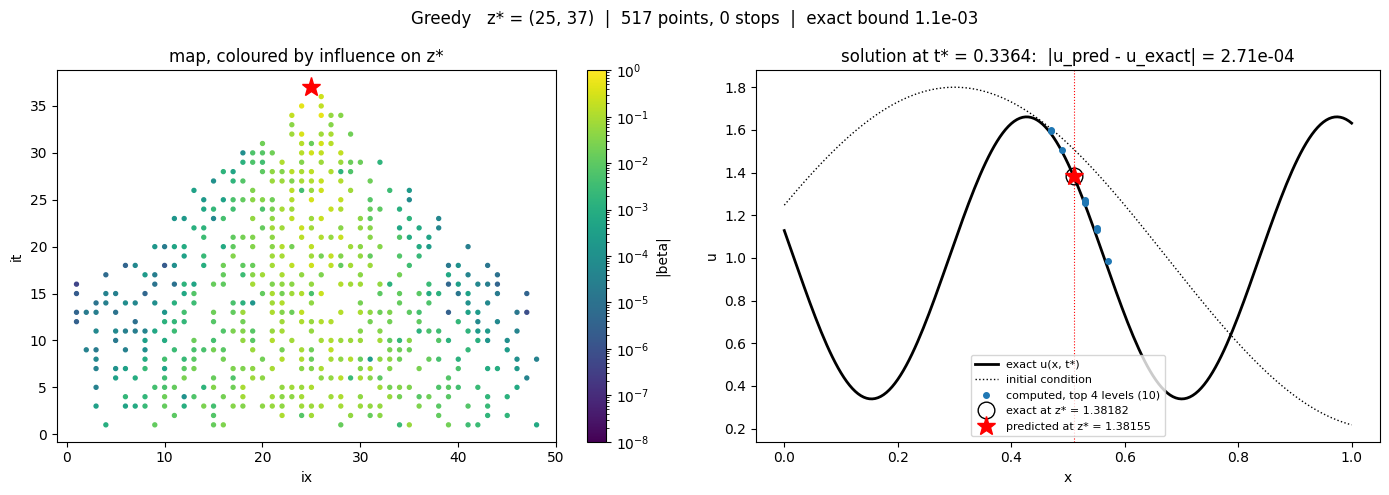

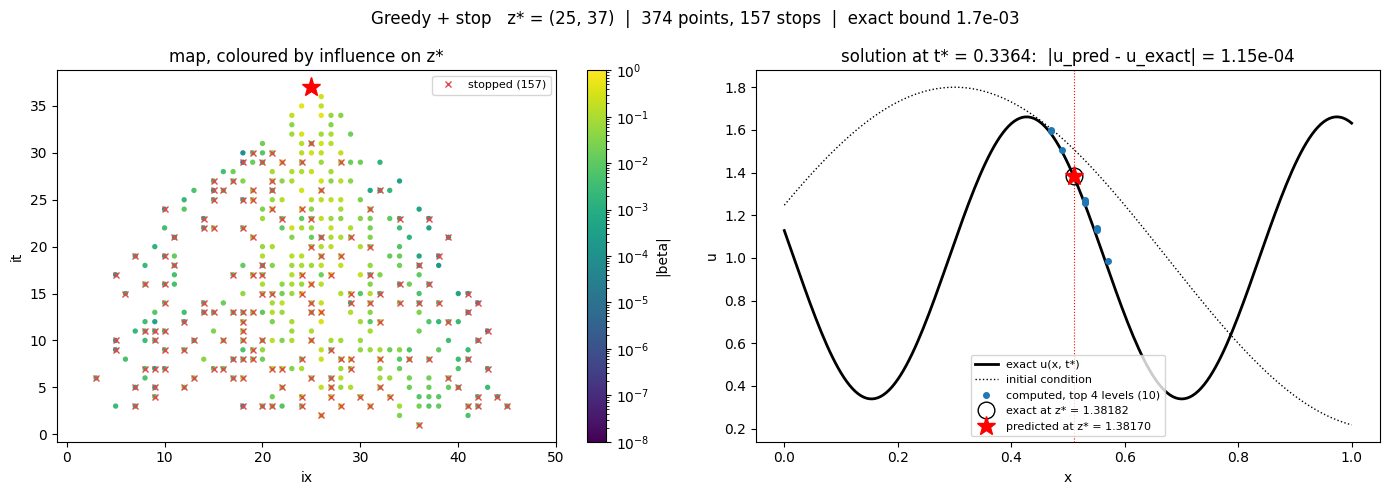

In [15]:
# ── One figure for any finished map (baselines, snapshots, training video) ──
#   left : the map, coloured by influence |beta| on z*; stopped points marked
#   right: the solution at t*: exact u(x, t*), the computed points of the top levels, and the value at z* (u_true ONLY here)
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None, top=4):
    z, rep = m["z_star"], report(m)
    u_hat = evaluate(m)
    P = np.array(list(m["stencil"]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

    sc = a1.scatter(P[:, 0], P[:, 1], c=[abs(m["beta"][tuple(p)]) for p in P], s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    if m["stopped"]:
        S = np.array(list(m["stopped"]))
        a1.plot(S[:, 0], S[:, 1], "x", color="#e34948", ms=4, label=f"stopped ({len(S)})")
        a1.legend(fontsize=8)
    a1.plot(*z, "r*", ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlim(-1, nx); a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("map, coloured by influence on z*")

    xf = np.linspace(0, 1, 201)
    a2.plot(xf, u_true(xf, z[1] * dt), "k-", lw=2, label="exact u(x, t*)")
    a2.plot(xf, u0(xf), "k:", lw=1, label="initial condition")
    near = [p for p in u_hat if p[1] >= z[1] - top]
    a2.plot([p[0] * dx for p in near], [u_hat[p] for p in near], "o", color="C0", ms=4, label=f"computed, top {top} levels ({len(near)})")
    a2.plot(z[0] * dx, Ug(z), "ko", ms=12, mfc="none", label=f"exact at z* = {Ug(z):.5f}")
    a2.plot(z[0] * dx, u_hat[z], "r*", ms=14, label=f"predicted at z* = {u_hat[z]:.5f}")
    a2.axvline(z[0] * dx, color="r", ls=":", lw=0.8)
    a2.set_xlabel("x"); a2.set_ylabel("u"); a2.legend(fontsize=8)
    a2.set_title(f"solution at t* = {z[1] * dt:.4f}:  |u_pred - u_exact| = {rep['error']:.2e}")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points, {len(m['stopped'])} stops  |  exact bound {rep['bound']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

z = (25, 37)
for name, rule in [("Wide 5-point", wide), ("Greedy", greedy_rule(1.0)), ("Greedy + stop", greedy_stop_rule(1.0))]:
    plot_map(build_map(z, rule), name)

### Training helpers
- `make_env`: one training environment (action mask + episode monitor); the switches (`stops`, `shaping`, `points_cost`) are passed through.
- `run_policy`: one episode with the policy's most likely picks, **without shaping** (the real return), same switches otherwise.
- `MapLogCallback`: points, accuracy term, stops, mean depth and finish rate of the training episodes (mean of the last 100) → TensorBoard.
- `SnapshotCallback`: every `every` steps, the policy at the training query and at one unseen query (watching only): numbers, map figure, checkpoint. The checkpoint with the best **training-query return** is kept as `best` (no exact solution in the selection); the last model is always reported too.

Check: a tiny run (2 environments, 512 steps, one snapshot).

In [16]:
# ── Training helpers ──
import json

def make_env(queries, seed, **env_kw):
    """One training environment (with the action mask and the episode monitor). env_kw: stops, shaping, points_cost, lam_range."""
    def _init():
        env = Monitor(ActionMasker(MapEnv(queries=queries, **env_kw), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, **env_kw):
    """One episode on z* with the policy's most likely picks, WITHOUT shaping (the real return). Returns the finished env."""
    env = MapEnv(queries=[z], **{**env_kw, "shaping": None})
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        act, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(act)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: numbers of every finished training episode, mean of the last 100, to TensorBoard ──
class MapLogCallback(BaseCallback):
    KEYS = ("points_ratio", "score_ratio", "stops", "depth", "finished")
    def __init__(self):
        super().__init__()
        self.hist = {k: [] for k in self.KEYS}
    def _on_step(self):
        for info, done in zip(self.locals["infos"], self.locals["dones"]):
            if done and "points_ratio" in info:
                for k in self.KEYS:
                    self.hist[k].append(float(info[k]))
                    self.logger.record(f"map/{k}", np.mean(self.hist[k][-100:]))
        return True

# ── Callback 2: every `every` steps, the deterministic policy on the training query and one unseen query ──
#   saves the map figures and a checkpoint; keeps the checkpoint with the best TRAINING-query return as "best"
#   (selection uses estimates only; the unseen query and the true error are for watching, never for selection)
class SnapshotCallback(BaseCallback):
    def __init__(self, every, z_train, z_watch, folder, env_kw):
        super().__init__()
        self.every, self.z_train, self.z_watch, self.folder, self.env_kw = every, z_train, z_watch, folder, env_kw
        self.next, self.best, self.rows = every, -np.inf, []
        os.makedirs(folder, exist_ok=True)
    def _on_step(self):
        if self.num_timesteps < self.next:
            return True
        self.next += self.every
        steps = self.num_timesteps
        self.model.save(os.path.join(self.folder, f"ckpt_{steps}"))
        for z in (self.z_train, self.z_watch):
            env = run_policy(self.model, z, **self.env_kw)
            rep = report(env.m)
            row = {"steps": steps, "z": list(z), "return": env.ret, "points": rep["points"], "stops": env.info["stops"],
                   "depth": env.info["depth"], "error": rep["error"], "bound": rep["bound"]}
            self.rows.append(row)
            tag = "train" if z == self.z_train else "watch"
            for k in ("return", "points", "stops", "depth", "error", "bound"):
                self.logger.record(f"snap_{tag}/{k}", row[k])
            plot_map(env.m, f"{steps:,} steps ({tag})", path=os.path.join(self.folder, f"snap_{tag}_{steps:09d}.png"))
            print(f"{steps:>10,} | {tag} z* = {z}: return {env.ret:7.3f}, {rep['points']} points, {env.info['stops']} stops, "
                  f"depth {env.info['depth']:.2f}, error {rep['error']:.2e}, bound {rep['bound']:.2e}")
            if z == self.z_train and env.ret > self.best:
                self.best = env.ret
                self.model.save(os.path.join(self.folder, "best"))
        with open(os.path.join(self.folder, "snapshots.json"), "w") as f:
            json.dump(self.rows, f)
        return True


In [33]:
# ── Training: the menu agent on advection-diffusion (pass-1 guess), MULTI-QUERY, seeds 1, 3, 5, 10M steps each ──
#   trained on the 4 queries of Z_MULTI (env cell); best.zip chosen on Z_TRAIN; Z_WATCH unseen, watched only
#   each run is skipped if its final.zip exists and resumes from its newest checkpoint after a crash
RUN_ROOT = f"runs{date.today():%m-%d}"
Z_TRAIN, Z_WATCH = (25, 30), (25, 50)
SEEDS, STEPS, EVERY, N_ENVS = (1, 3, 5), 10_000_000, 100_000, 8
PPO_KW = dict(n_steps=1024, batch_size=1024, gamma=1.0, gae_lambda=1.0, learning_rate=3e-4, ent_coef=0.0)
KW = dict(stops=False, shaping=None, points_cost="step", menu=MENU)
seed_dir = lambda name, z, seed: os.path.join(RUN_ROOT, f"nb16_adv_{SPEED}_{name}_z{z[0]}-{z[1]}_eps{EPS:.0e}_seed{seed}_pass1")

def train(name, queries, z_select, kw, seed, steps):
    """One training run on `queries`; snapshots (and best.zip) on z_select and Z_WATCH."""
    folder = seed_dir(name, z_select, seed)
    if os.path.exists(os.path.join(folder, "final.zip")):
        print(f"{name} seed {seed}: already done, skipped", flush=True); return
    vec = SubprocVecEnv([make_env(queries, seed=seed * 100 + i, **kw) for i in range(N_ENVS)])
    snap = SnapshotCallback(EVERY, z_select, Z_WATCH, folder, kw)
    ckpts = [f for f in os.listdir(folder) if f.startswith("ckpt_")] if os.path.isdir(folder) else []
    if ckpts:                                                          # resume after a crash
        model = MaskablePPO.load(os.path.join(folder, max(ckpts, key=lambda f: int(f[5:-4]))), env=vec, tensorboard_log=RUN_ROOT)
        snap.rows = json.load(open(os.path.join(folder, "snapshots.json")))
        snap.best = max(r["return"] for r in snap.rows if tuple(r["z"]) == z_select)
        snap.next = model.num_timesteps + EVERY
    else:
        model = MaskablePPO("MlpPolicy", vec, seed=seed, verbose=0, tensorboard_log=RUN_ROOT, **PPO_KW)
    t0 = time.time()
    print(f"=== {name} seed {seed}: {model.num_timesteps:,} -> {steps:,} steps -> {folder}", flush=True)
    model.learn(steps - model.num_timesteps, callback=[MapLogCallback(), snap], tb_log_name=os.path.basename(folder),
                reset_num_timesteps=not ckpts)
    model.save(os.path.join(folder, "final")); vec.close()
    print(f"=== {name} seed {seed}: done in {(time.time() - t0) / 60:.0f} min", flush=True)

print(f"{SPEED}: training on {Z_MULTI}, menu of {len(MENU)} shapes (greedy's shapes at the training queries)")
for seed in SEEDS:
    try:
        train("menu_multi", Z_MULTI, Z_TRAIN, KW, seed, STEPS)
    except Exception as e:                                             # one failing seed must not stop the night
        print(f"=== menu_multi seed {seed}: FAILED: {e!r}", flush=True)

ou: training on [(25, 30), (15, 25), (35, 25), (25, 20)], menu of 918 shapes (greedy's shapes at the training queries)
=== menu_multi seed 1: 0 -> 10,000,000 steps -> runs11-13\nb16_adv_ou_menu_multi_z25-30_eps1e-03_seed1_pass1
   100,000 | train z* = (25, 30): return  -3.811, 994 points, 0 stops, depth 1.72, error 2.15e-03, bound 2.96e-03
   100,000 | watch z* = (25, 50): return  -8.254, 1954 points, 0 stops, depth 1.75, error 6.55e-03, bound 9.45e-03
   200,000 | train z* = (25, 30): return  -9.183, 1023 points, 0 stops, depth 1.73, error 7.02e-03, bound 1.00e-02
   200,000 | watch z* = (25, 50): return -109.667, 1982 points, 0 stops, depth 1.78, error 3.40e-02, bound 1.40e-01
   300,000 | train z* = (25, 30): return  -2.746, 772 points, 0 stops, depth 1.75, error 1.31e-03, bound 2.06e-03
   300,000 | watch z* = (25, 50): return  -9.030, 1660 points, 0 stops, depth 1.75, error 9.10e-03, bound 1.12e-02
   400,000 | train z* = (25, 30): return  -4.978, 885 points, 0 stops, depth 1.71, 

In [17]:
SEEDS = (1, 3, 5)
KW = dict(stops=False, shaping=None, points_cost="step", menu=MENU)

seed 1: runs11-13\nb16_adv_ou_menu_multi_z25-30_eps1e-03_seed1_pass1\best.zip
seed 3: runs11-13\nb16_adv_ou_menu_multi_z25-30_eps1e-03_seed3_pass1\best.zip
seed 5: runs11-13\nb16_adv_ou_menu_multi_z25-30_eps1e-03_seed5_pass1\best.zip

method           | at (25, 30): total pts     error     bound | 9 unseen: err / best explicit | pts / greedy bound / greedy
wide-5 map       |                   1140  1.72e-03  1.74e-03 |           x  2.800 (9/9) | x       2.25 x         3.47
lowest score     |                   1096  2.36e-04  3.50e-04 |           x  0.263 (9/9) | x       2.18 x         0.79
greedy           |                    531  1.60e-04  4.80e-04 |           x  0.119 (9/9) | x       1.00 x         1.00
agent seed 1     |                    729  2.34e-04  7.38e-04 |           x  0.778 (9/9) | x       1.44 x         2.13
agent seed 3     |                    704  9.66e-05  2.23e-04 |           x  0.268 (9/9) | x       1.32 x         1.30
agent seed 5     |                    576  4.9

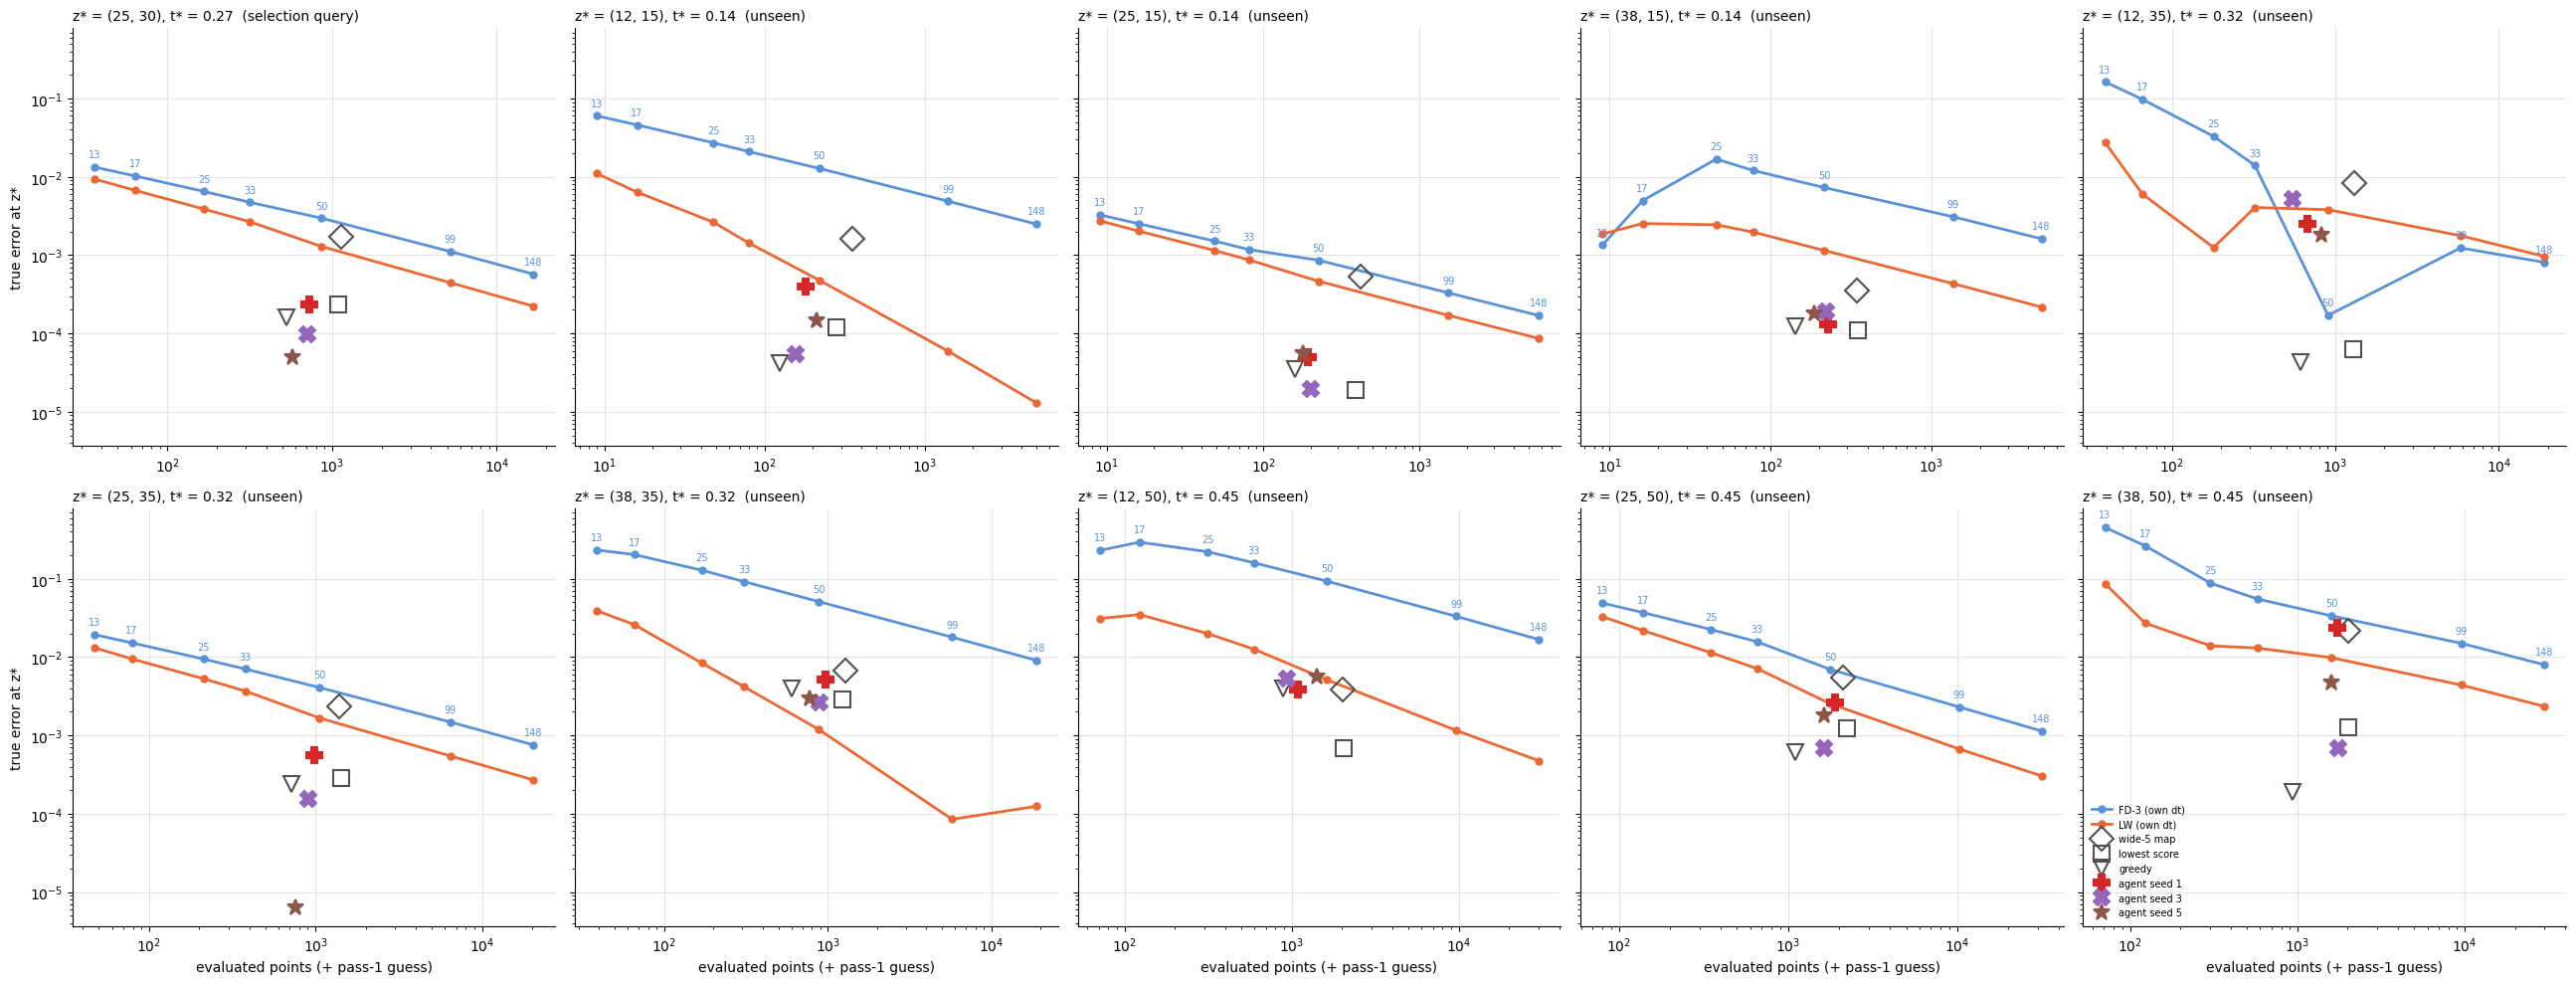

In [18]:
# ── Advection: every method vs the explicit schemes (FD-3, LW at their own stable dt), training query + 9 unseen ──
#    agents = the 3 multi-query seeds (best.zip); map methods pay their pass-1 points (wide-5 needs no guess: speed known)
import glob
Z_TRAIN = (25, 30)
TEST_QUERIES = [(ix, it) for it in (15, 35, 50) for ix in (12, 25, 38)]
Z_ALL = [Z_TRAIN] + TEST_QUERIES

def classical(scheme, n, z):
    """(evaluated points in the cone, true error at z*'s position): explicit FD-3 or LW on n nodes, 0.95 of its own limit."""
    h = 1.0 / (n - 1)
    c2, c1 = (A_MAX / h)**2, 2 * alpha / h**2
    t_star, ix = z[1] * dt, round(z[0] * dx / h)
    steps = int(np.ceil(t_star / (0.95 * (-c1 + np.sqrt(c1**2 + 4 * c2)) / (2 * c2))))
    tau = t_star / steps
    r, nu = alpha * tau / h**2, speed(np.arange(1, n - 1) * h) * tau / h
    u = u0(np.arange(n) * h)
    for j in range(steps):
        d2, d1 = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
        u = u.copy()
        if scheme == "FD-3":
            u[1:-1] = u[1:-1] + r * d2 - nu * d1
        else:                                                         # LW with the a a' term
            u[1:-1] = u[1:-1] + (r + nu**2 / 2) * d2 - nu * (1 - A_PRIME * tau / 2) * d1
        u[0], u[-1] = g_left((j + 1) * tau), g_right((j + 1) * tau)
    pts = sum(min(n - 2, ix + j) - max(1, ix - j) + 1 for j in range(steps))   # cone grows one cell per step
    return pts, abs(u[ix] - u_true(ix * h, t_star)[0])

N_GRID = (13, 17, 25, 33, 50, 99, 148)
SCHEMES = {"FD-3": "#5a92d8", "LW": "#eb6834"}
CL = {z: {s: [classical(s, n, z) for n in N_GRID] for s in SCHEMES} for z in Z_ALL}
def error_at(z, pts):                                                # best explicit (min of FD-3, LW per grid), log-log interp
    P = np.log([p for p, _ in CL[z]["FD-3"]])
    E = np.log(np.minimum([e for _, e in CL[z]["FD-3"]], [e for _, e in CL[z]["LW"]]))
    return float(np.exp(np.interp(np.log(pts), P, E, left=np.nan, right=np.nan)))

def evaluate_rule(rule, z, guess=True):
    rep = report(build_map(z, rule))
    return rep | {"total": rep["points"] + (use_guess(z) if guess else 0)}
def evaluate_model(path, z):
    env = run_policy(MaskablePPO.load(path), z, **KW)
    rep = report(env.m)
    return rep | {"total": rep["points"] + use_guess(z), "return": env.ret}

ALL = {"wide-5 map": {z: evaluate_rule(wide, z, guess=False) for z in Z_ALL},
       "lowest score": {z: evaluate_rule(lowest_score, z) for z in Z_ALL},
       "greedy": {z: evaluate_rule(greedy_rule(1.0), z) for z in Z_ALL}}
for s in SEEDS:
    found = sorted(glob.glob(os.path.join("runs*", f"nb16_adv_{SPEED}_menu_multi_z25-30_eps{EPS:.0e}_seed{s}_pass1", "best.zip")))
    if not found:
        print(f"seed {s}: no best.zip found, skipped"); continue
    print(f"seed {s}: {found[-1]}")
    ALL[f"agent seed {s}"] = {z: evaluate_model(found[-1], z) for z in Z_ALL}

# ── Table: each method at the training query; over the 9 unseen: vs the best explicit at the same cost, and vs greedy ──
gm = lambda v: float(np.exp(np.mean(np.log([x for x in v if np.isfinite(x)])))) if any(np.isfinite(v)) else np.nan
G = ALL["greedy"]
print(f"\n{'method':16s} | at {Z_TRAIN}: {'total pts':>9s} {'error':>9s} {'bound':>9s} | 9 unseen: "
      f"{'err / best explicit':>19s} | {'pts / greedy':>12s} {'bound / greedy':>14s}")
for name, rs in ALL.items():
    r = rs[Z_TRAIN]
    e = [rs[z]["error"] / error_at(z, rs[z]["total"]) for z in TEST_QUERIES]
    print(f"{name:16s} | {'':{len(str(Z_TRAIN)) + 5}s}{r['total']:9d} {r['error']:9.2e} {r['bound']:9.2e} | "
          f"{'':10s}x{gm(e):7.3f} ({sum(np.isfinite(e))}/9) | "
          f"x{gm([rs[z]['total'] / G[z]['total'] for z in TEST_QUERIES]):11.2f} x{gm([rs[z]['bound'] / G[z]['bound'] for z in TEST_QUERIES]):13.2f}")

# ── Figure: error vs evaluated points, one panel per query; explicit grids labelled with nx ──
MK = dict(zip(ALL, ["D", "s", "v", "P", "X", "*"]))
fig_a, axes_a = plt.subplots(2, 5, figsize=(26, 10), sharey=True)
for ax, z in zip(axes_a.flat, Z_ALL):
    for s_, col in SCHEMES.items():
        ax.loglog(*zip(*CL[z][s_]), "o-", color=col, lw=2, ms=5, label=f"{s_} (own dt)")
    for n, (p, e) in zip(N_GRID, CL[z]["FD-3"]):
        ax.annotate(f"{n}", (p, e), textcoords="offset points", xytext=(0, 7), fontsize=7, color="#5a92d8", ha="center")
    for i, (name, rs) in enumerate(ALL.items()):
        ag = name.startswith("agent")
        ax.loglog(rs[z]["total"], rs[z]["error"], MK[name], color=plt.cm.tab10(i) if ag else "#52514e",
                  ms=12, mfc=None if ag else "none", mew=1.5, label=name)
    ax.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}  ({'selection query' if z == Z_TRAIN else 'unseen'})", loc="left", fontsize=10)
    ax.grid(True, which="major", color="#e5e4df", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
for ax in axes_a[1]:
    ax.set_xlabel("evaluated points (+ pass-1 guess)")
for ax in axes_a[:, 0]:
    ax.set_ylabel("true error at z*")
axes_a.flat[-1].legend(fontsize=7, frameon=False, loc="lower left")
fig_a.tight_layout()
fig_a.savefig(f"comparison_adv_{SPEED}.png", dpi=90)
plt.show()

DWR at (25, 30):
    13 nodes | points: this mesh      72, whole loop       72 | error 1.53e-02
    16 nodes | points: this mesh      72, whole loop      144 | error 1.29e-02
    19 nodes | points: this mesh     364, whole loop      508 | error 5.58e-03
    23 nodes | points: this mesh    2156, whole loop     2664 | error 1.32e-03
    28 nodes | points: this mesh   11286, whole loop    13950 | error 3.95e-04
    34 nodes | points: this mesh   56664, whole loop    70614 | error 2.91e-04
    41 nodes | points: this mesh   68922, whole loop   139536 | error 2.96e-04

method           | 9 unseen, error / DWR error at the same points:  last mesh  whole loop
wide-5 map       |                                                 x   0.329 (9/9) x  0.294 (9/9)
lowest score     |                                                 x   0.031 (9/9) x  0.028 (9/9)
greedy           |                                                 x   0.017 (9/9) x  0.014 (9/9)
agent seed 1     |                           

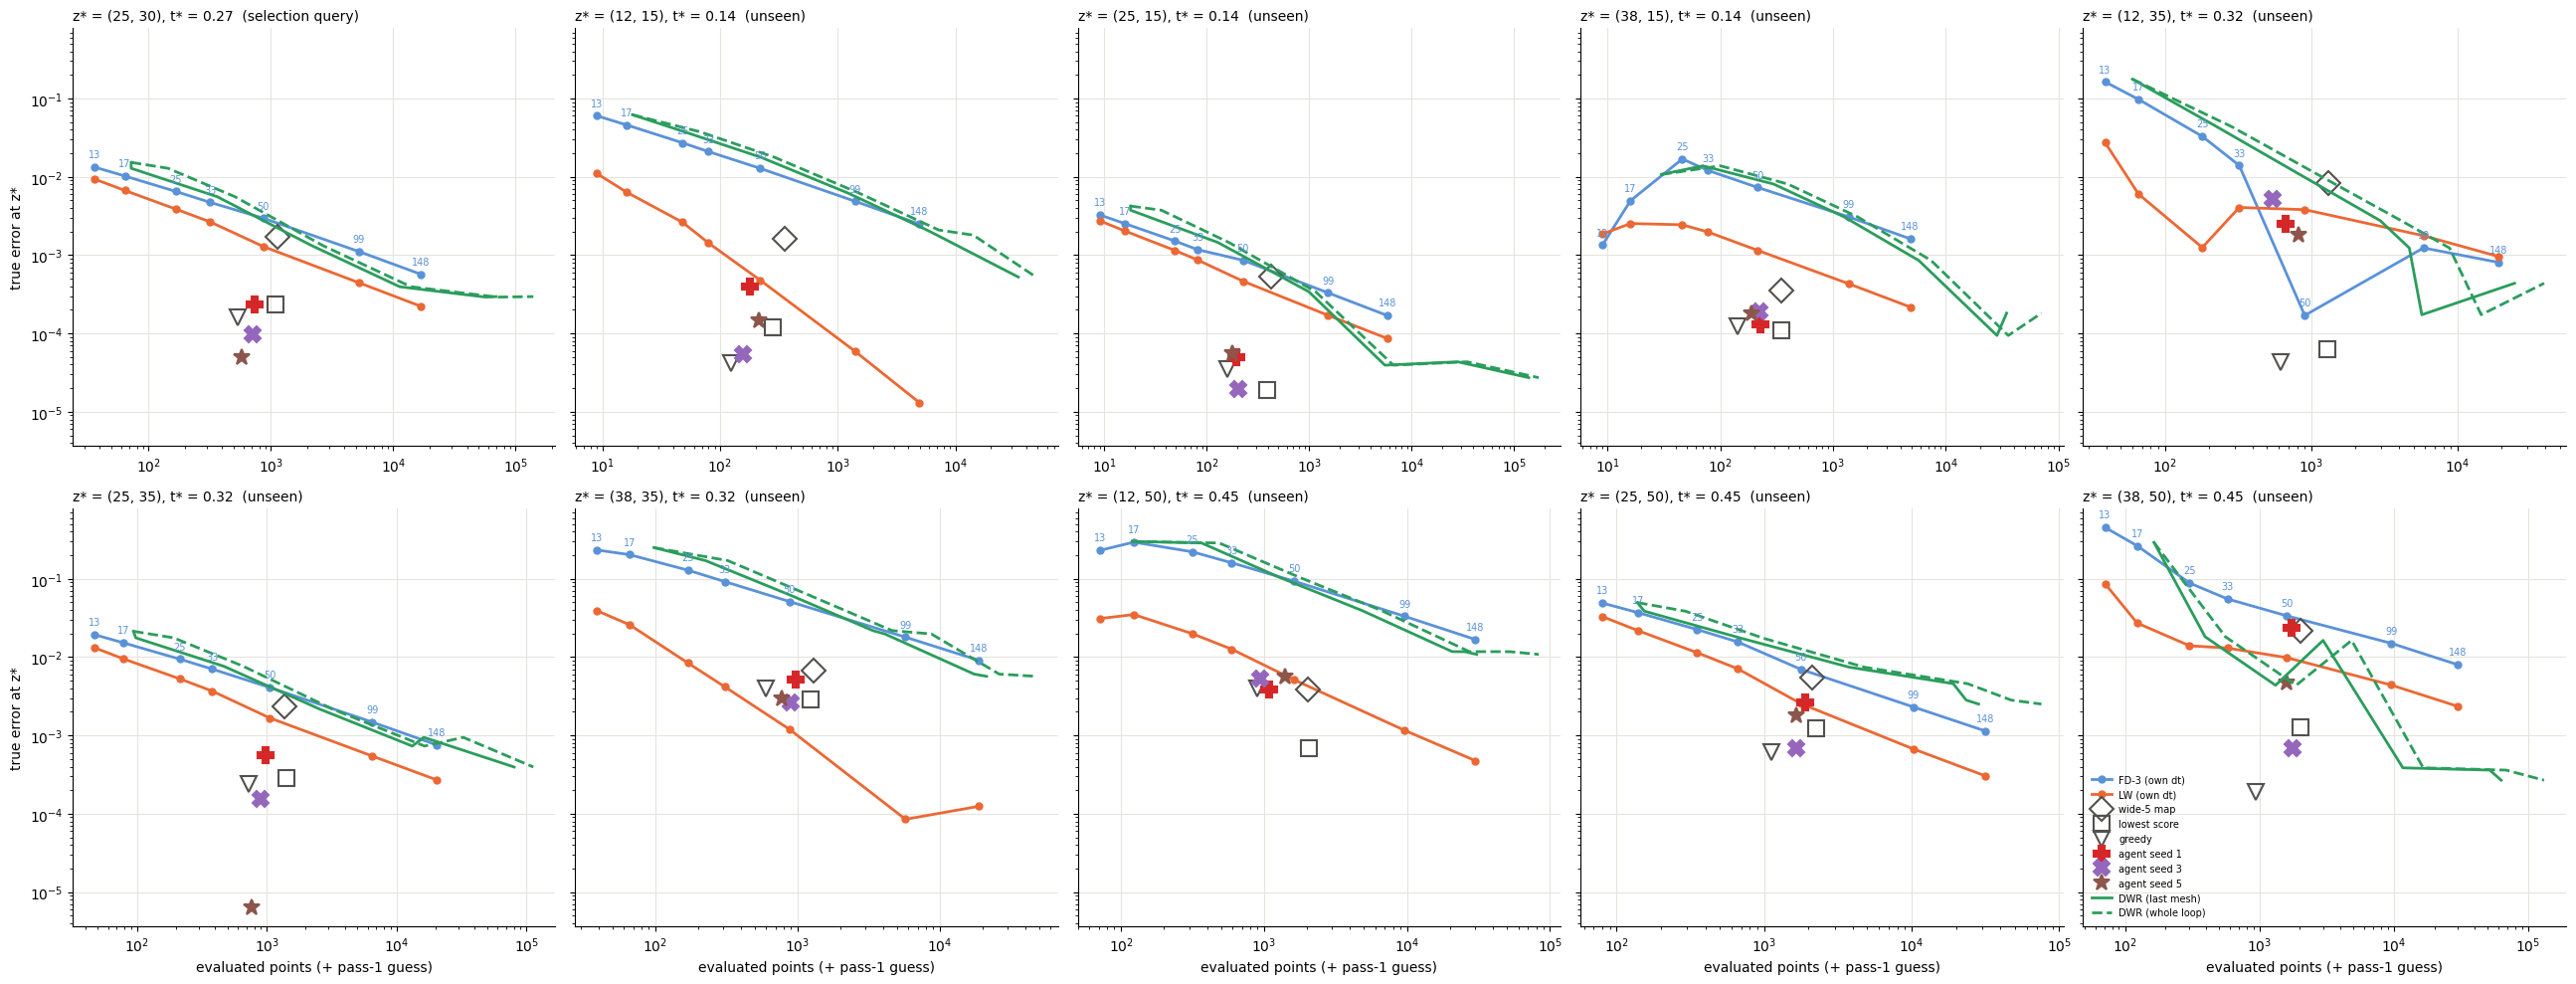

In [19]:
# ── DWR baseline: goal-oriented adaptive mesh (Becker & Rannacher) for J(u) = u(x*, t*), with explicit FD-3 ──
#   loop: solve the primal on a nonuniform x-mesh (FD-3, forward Euler, 0.9 of its stable dt) -> solve the discrete
#   adjoint backward from z* -> indicators eta_i = sum_n |adjoint_i * estimated local error_i| -> bisect the cells
#   with the largest eta (top DWR_FRAC) -> repeat.  The local error is estimated from the COMPUTED solution
#   (Taylor terms of the scheme, derivatives from a spline of u_h): no exact solution, like our score.
#   cost: points in z*'s dependence cone, primal + adjoint, per iteration; reported for the last mesh alone and
#   summed over all iterations (what the loop really costs)
from scipy.interpolate import make_interp_spline
DWR_ITERS, DWR_FRAC, DWR_N0 = 7, 0.2, 13

def dwr_start_mesh(x_star, n0=DWR_N0):
    """Uniform mesh through x* (spacing 1 / (n0 - 1)), plus the walls; nodes closer than h/2 to a wall dropped."""
    h = 1.0 / (n0 - 1)
    x = x_star + h * np.arange(-n0, n0 + 1)
    x = x[(x > h / 2) & (x < 1 - h / 2)]
    return np.r_[0.0, x, 1.0]

def dwr_solve(x, z):
    """Primal FD-3 on the mesh x up to t*, its discrete adjoint for J = u(x*, t*), and the DWR indicator per node.
    Returns u_h(x*, t*), the indicators (per node), and the cone points of one solve."""
    x_star, t_star = z[0] * dx, z[1] * dt
    i_s = int(np.argmin(np.abs(x - x_star)))
    hm, hp = np.diff(x)[:-1], np.diff(x)[1:]                      # spacings left / right of the interior nodes
    xi, ai = x[1:-1], speed(x[1:-1])
    d1 = np.stack([-hp / (hm * (hm + hp)), (hp - hm) / (hm * hp), hm / (hp * (hm + hp))], 1)   # u_x weights (i-1, i, i+1)
    d2 = np.stack([2 / (hm * (hm + hp)), -2 / (hm * hp), 2 / (hp * (hm + hp))], 1)             # u_xx weights
    Wn = -ai[:, None] * d1 + alpha * d2                           # u_t = sum_k Wn[:, k] u_{i-1+k}
    q2, q1 = ai**2 / (hm * hp), 2 * alpha / (hm * hp)             # stability 2r + nu^2 <= 1 per node, 0.9 margin
    tau_max = np.min((-q1 + np.sqrt(q1**2 + 4 * q2 * 0.9)) / (2 * q2 + 1e-300) if np.any(q2 > 0) else 0.9 / q1)
    steps = int(np.ceil(t_star / tau_max)); tau = t_star / steps
    N = len(x)
    A = np.zeros((N, N))                                          # one step: u^{n+1} = A u^n (interior rows), walls = data
    for k in range(3):
        A[np.arange(1, N - 1), np.arange(k, N - 2 + k)] += tau * Wn[:, k]
    A[np.arange(1, N - 1), np.arange(1, N - 1)] += 1.0
    U = np.empty((steps + 1, N)); U[0] = u0(x)
    for n in range(steps):
        U[n + 1] = A @ U[n]
        U[n + 1, 0], U[n + 1, -1] = g_left((n + 1) * tau), g_right((n + 1) * tau)
    Z = np.zeros((steps + 1, N)); Z[steps, i_s] = 1.0             # adjoint: z^n = A^T z^{n+1} on the interior
    for n in range(steps - 1, -1, -1):
        Z[n] = A.T @ Z[n + 1]; Z[n, 0] = Z[n, -1] = 0.0
    # local error of one step at interior node i, estimated from the computed solution:
    #   delta = tau^2/2 u_tt + tau (a e1 - alpha e2),  e1 = hm hp/6 u_xxx,  e2 = (hp - hm)/3 u_xxx + (hm^2 - hm hp + hp^2)/12 u_xxxx
    stride = max(1, steps // 200)                                 # indicators on every stride-th step (x stride)
    eta = np.zeros(N)
    for n in range(0, steps, stride):
        sp = make_interp_spline(x, U[n], k=5)
        D = [sp.derivative(k)(xi) for k in range(1, 5)]           # u_x .. u_xxxx at the interior nodes
        uxt  = -A_PRIME * D[0] - ai * D[1] + alpha * D[2]
        uxxt = -2 * A_PRIME * D[1] - ai * D[2] + alpha * D[3]
        utt  = -ai * uxt + alpha * uxxt
        e1 = hm * hp / 6 * D[2]
        e2 = (hp - hm) / 3 * D[2] + (hm**2 - hm * hp + hp**2) / 12 * D[3]
        delta = tau**2 / 2 * utt + tau * (ai * e1 - alpha * e2)
        eta[1:-1] += stride * np.abs(Z[n + 1, 1:-1] * delta)
    pts = sum(min(N - 2, i_s + j) - max(1, i_s - j) + 1 for j in range(steps))   # dependence cone, one node per step
    return U[steps, i_s], eta, pts

def dwr(z, iters=DWR_ITERS, frac=DWR_FRAC):
    """DWR refinement loop at z*: [(nodes, points of this mesh, points summed over all iterations, true error)]."""
    x = dwr_start_mesh(z[0] * dx)
    rows, total = [], 0
    for _ in range(iters):
        u_s, eta, pts = dwr_solve(x, z)
        total += 2 * pts                                          # primal + adjoint
        rows.append((len(x), 2 * pts, total, abs(u_s - u_true(z[0] * dx, z[1] * dt)[0])))
        cell = (eta[:-1] + eta[1:]) / 2                           # indicator per cell
        top = np.argsort(cell)[::-1][:max(1, int(np.ceil(frac * len(cell))))]
        x = np.sort(np.r_[x, (x[top] + x[top + 1]) / 2])          # bisect the marked cells
    return rows

# ── Run DWR at every query; each method vs DWR at the same cost (log-log interpolation on DWR's curve) ──
DWR = {z: dwr(z) for z in Z_ALL}
def dwr_error_at(z, pts, col):                                    # col 1 = last mesh only, col 2 = summed over the loop
    P = np.log([r[col] for r in DWR[z]]); E = np.log([r[3] for r in DWR[z]])
    o = np.argsort(P)
    return float(np.exp(np.interp(np.log(pts), P[o], E[o], left=np.nan, right=np.nan)))

print(f"DWR at {Z_TRAIN}:")
for r in DWR[Z_TRAIN]:
    print(f"   {r[0]:3d} nodes | points: this mesh {r[1]:7d}, whole loop {r[2]:8d} | error {r[3]:.2e}")
print(f"\n{'method':16s} | 9 unseen, error / DWR error at the same points: {'last mesh':>10s} {'whole loop':>11s}")
for name, rs in ALL.items():
    a_ = [rs[z]["error"] / dwr_error_at(z, rs[z]["total"], 1) for z in TEST_QUERIES]
    b_ = [rs[z]["error"] / dwr_error_at(z, rs[z]["total"], 2) for z in TEST_QUERIES]
    print(f"{name:16s} | {'':47s} x{gm(a_):8.3f} ({sum(np.isfinite(a_))}/9) x{gm(b_):7.3f} ({sum(np.isfinite(b_))}/9)")

# ── Figure: the comparison figure + DWR (solid: last mesh only, dashed: whole loop) ──
for ax, z in zip(axes_a.flat, Z_ALL):
    ax.loglog([r[1] for r in DWR[z]], [r[3] for r in DWR[z]], "-", color="#2a9d5c", lw=2, label="DWR (last mesh)")
    ax.loglog([r[2] for r in DWR[z]], [r[3] for r in DWR[z]], "--", color="#2a9d5c", lw=2, label="DWR (whole loop)")
axes_a.flat[-1].legend(fontsize=7, frameon=False, loc="lower left")
fig_a.savefig(f"comparison_adv_{SPEED}_dwr.png", dpi=90)
fig_a

DWR (explicit, 8 slabs) at (25, 30):
    104 nodes over the slabs | points: this solve     116, whole loop      116 | error 1.30e-02
    119 nodes over the slabs | points: this solve     120, whole loop      236 | error 9.62e-03
    136 nodes over the slabs | points: this solve     412, whole loop      648 | error 4.27e-03
    156 nodes over the slabs | points: this solve    1674, whole loop     2322 | error 2.27e-03
    179 nodes over the slabs | points: this solve    6508, whole loop     8830 | error 6.74e-04
    205 nodes over the slabs | points: this solve   17326, whole loop    26156 | error 7.99e-04
    235 nodes over the slabs | points: this solve   21062, whole loop    47218 | error 6.91e-04
    270 nodes over the slabs | points: this solve   62136, whole loop   109354 | error 3.61e-04
DWR (cn, 8 slabs) at (25, 30):
    104 nodes over the slabs | points: this solve     156, whole loop      156 | error 5.56e-03
    119 nodes over the slabs | points: this solve     392, whole loo

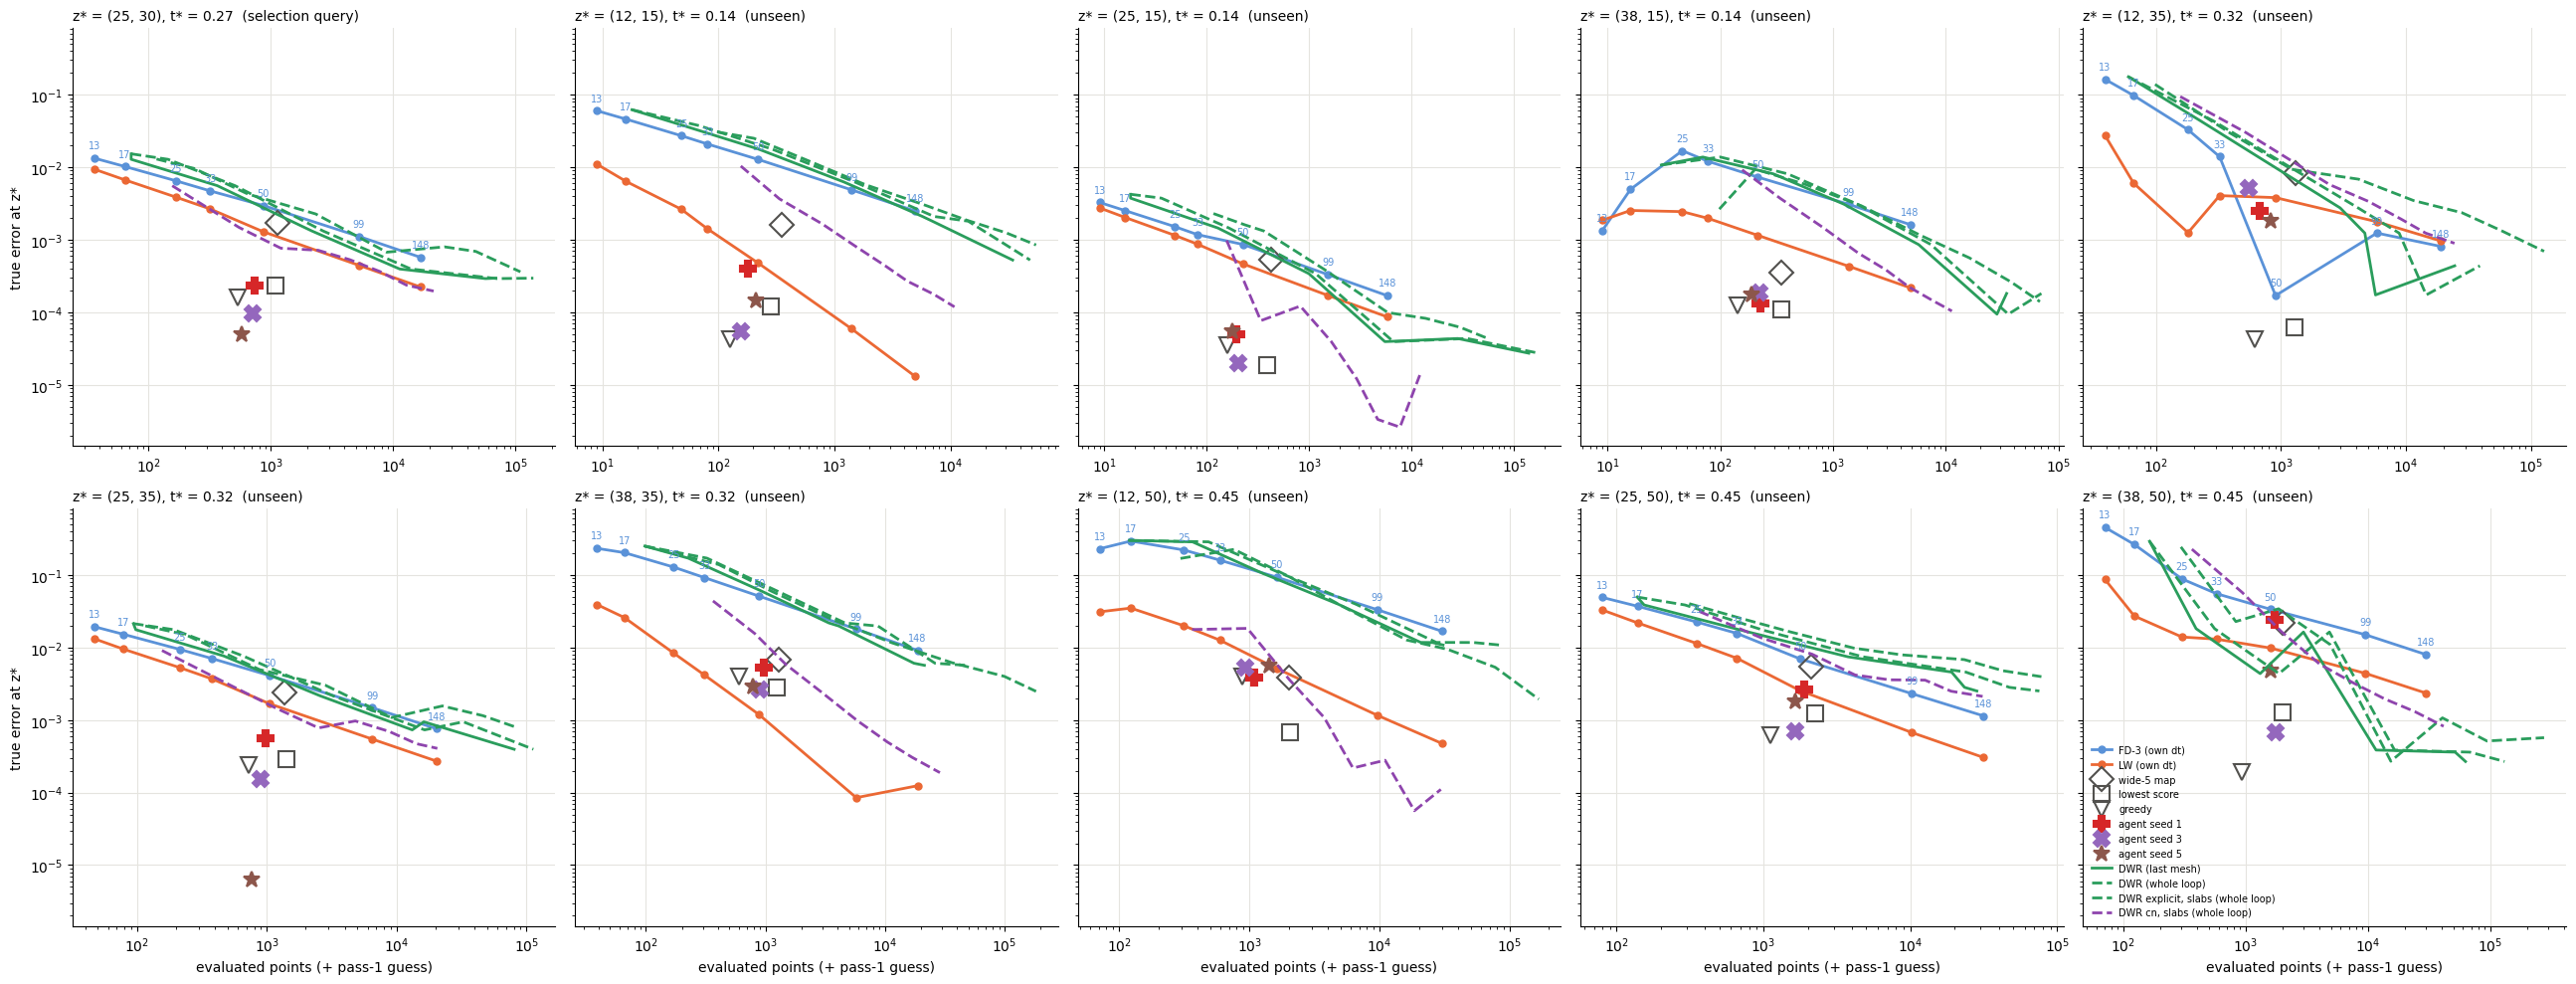

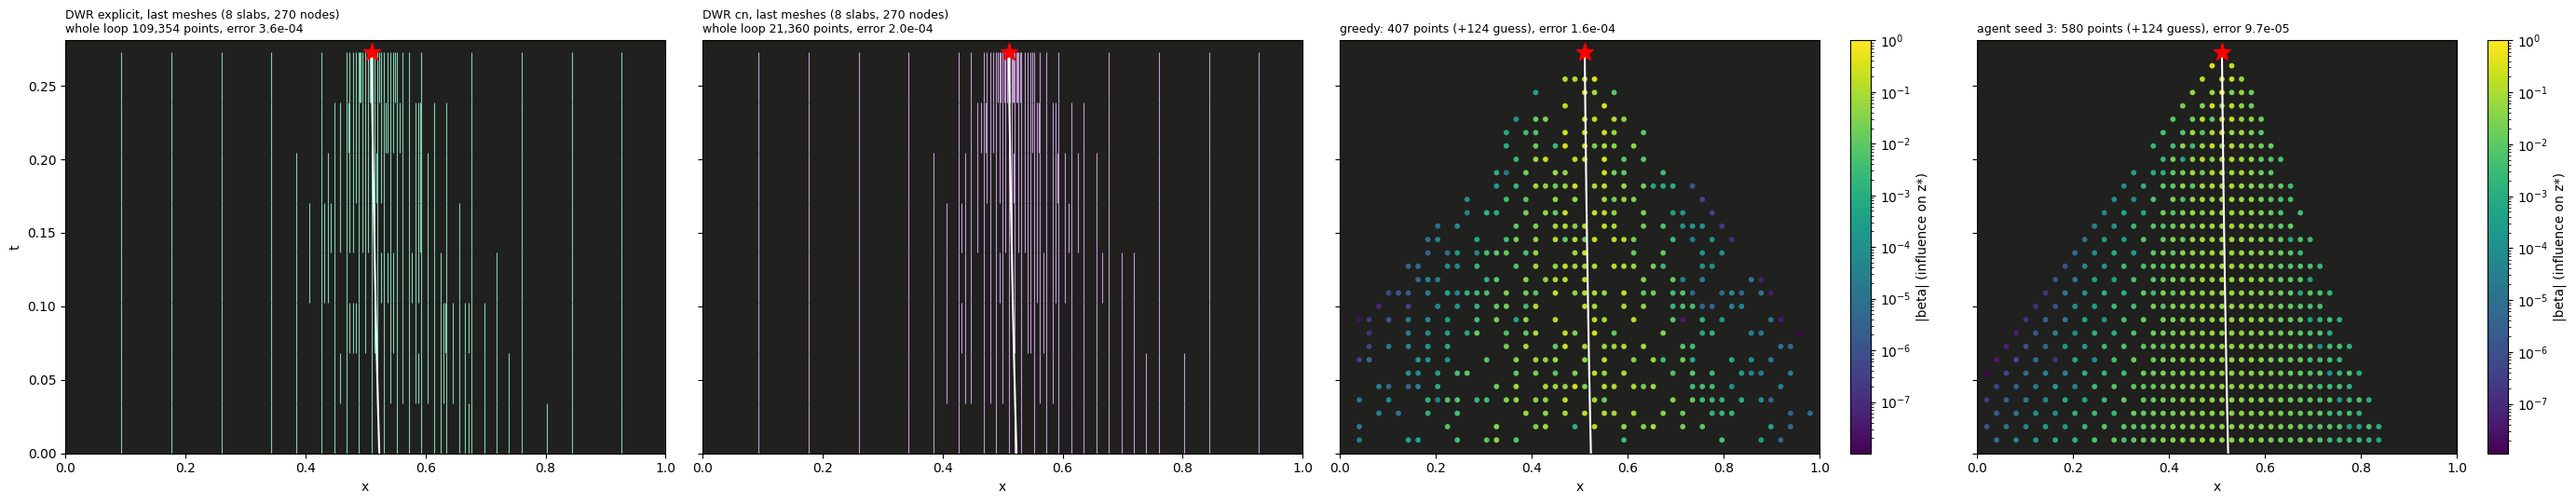

In [21]:
# ── DWR v2: goal-oriented adaptivity with TIME SLABS (own mesh per slab), explicit FD-3 or Crank-Nicolson ──
#   [0, t*] split into DWR_SLABS slabs; each slab has its own 1D mesh. Within a slab: FD-3 in space, time step
#     explicit: forward Euler at 0.9 of the slab's own stable step (the slab's smallest cell sets only that slab's step)
#     CN:       Crank-Nicolson, step = CN_C * (smallest cell of the slab) / A_MAX  (no stability limit; accuracy choice)
#   between slabs: local cubic interpolation onto the next mesh (and its transpose for the adjoint)
#   adjoint of the whole discrete solve for J = u(x*, t*); indicator per (slab, node) = sum over the slab's steps of
#   |adjoint x estimated local error|, the local error from the COMPUTED solution (no exact solution):
#     space part  tau (a e1 - alpha e2), e1, e2 = errors of the nonuniform u_x, u_xx (u_xxx, u_xxxx from a spline of u_h)
#     time part   explicit tau^2/2 u_tt, CN tau^3/12 u_ttt (u_tt, u_ttt from differences of u_h in time)
#   marking: the top DWR_FRAC of all (slab, cell) indicators are bisected.  cost per solve = points where the solution
#   matters for J (nonzero adjoint), primal + adjoint; reported for the last meshes alone and summed over the loop
from scipy.interpolate import make_interp_spline
DWR_SLABS, DWR_ITERS, DWR_FRAC, DWR_N0, CN_C = 8, 8, 0.15, 13, 1.0

def dwr_start_mesh(x_star, n0=DWR_N0):
    """Uniform mesh through x* (spacing 1 / (n0 - 1)), plus the walls; nodes closer than h/2 to a wall dropped."""
    h = 1.0 / (n0 - 1)
    x = x_star + h * np.arange(-n0, n0 + 1)
    x = x[(x > h / 2) & (x < 1 - h / 2)]
    return np.r_[0.0, x, 1.0]

def interp_matrix(x_new, x_old):
    """Local cubic Lagrange interpolation from x_old to x_new (4 nearest old nodes): P (len(x_new), len(x_old))."""
    P = np.zeros((len(x_new), len(x_old)))
    for i, xv in enumerate(x_new):
        j = np.argmin(np.abs(x_old - xv))
        if abs(x_old[j] - xv) < 1e-14:
            P[i, j] = 1.0; continue
        k = np.argsort(np.abs(x_old - xv))[:4]
        for a_ in k:
            P[i, a_] = np.prod([(xv - x_old[b]) / (x_old[a_] - x_old[b]) for b in k if b != a_])
    return P

def slab_ops(x, tau, scheme):
    """One-step map u^{n+1} = A u^n + B g^{n+1} (g = the two wall values) on mesh x, plus geometry for the indicators."""
    N = len(x)
    hm, hp = np.diff(x)[:-1], np.diff(x)[1:]
    ai = speed(x[1:-1])
    d1 = np.stack([-hp / (hm * (hm + hp)), (hp - hm) / (hm * hp), hm / (hp * (hm + hp))], 1)
    d2 = np.stack([2 / (hm * (hm + hp)), -2 / (hm * hp), 2 / (hp * (hm + hp))], 1)
    Wn = -ai[:, None] * d1 + alpha * d2
    W = np.zeros((N, N))                                          # u_t = W u on interior rows (walls: data)
    for k in range(3):
        W[np.arange(1, N - 1), np.arange(k, N - 2 + k)] += Wn[:, k]
    I = np.eye(N); Iw = np.zeros((N, N)); Iw[0, 0] = Iw[-1, -1] = 1.0
    Ii = I - Iw                                                   # interior projector
    E = np.zeros((N, 2)); E[0, 0] = E[-1, 1] = 1.0                # wall values enter the wall rows
    if scheme == "explicit":
        A = Ii @ (I + tau * W); B = E
    else:                                                         # CN: (I - tau/2 W) u^{n+1} = (I + tau/2 W) u^n on the interior
        Lhs = I - tau / 2 * W
        Lhs[0], Lhs[-1] = I[0], I[-1]
        Rhs = Ii @ (I + tau / 2 * W)
        A = np.linalg.solve(Lhs, Rhs); B = np.linalg.solve(Lhs, E)
    return A, B, hm, hp, ai

def slab_tau(x, scheme):
    hm, hp = np.diff(x)[:-1], np.diff(x)[1:]
    if scheme == "explicit":
        q2, q1 = speed(x[1:-1])**2 / (hm * hp), 2 * alpha / (hm * hp)
        return float(np.min((-q1 + np.sqrt(q1**2 + 4 * q2 * 0.9)) / (2 * q2 + 1e-300)))
    return CN_C * float(np.min(np.diff(x))) / A_MAX

def dwr2_solve(meshes, z, scheme):
    """Primal + adjoint over the slabs. Returns u_h(x*, t*), indicators [per slab: per node], cost of one solve."""
    x_star, t_star = z[0] * dx, z[1] * dt
    S = len(meshes); L = t_star / S
    plan = []                                                      # per slab: steps, tau, A, B, geometry
    for s, x in enumerate(meshes):
        steps = int(np.ceil(L / slab_tau(x, scheme))); tau = L / steps
        plan.append((steps, tau) + slab_ops(x, tau, scheme))
    U, u = [], u0(meshes[0])                                       # primal, all steps of every slab
    for s, x in enumerate(meshes):
        if s:
            u = interp_matrix(x, meshes[s - 1]) @ u
            u[0], u[-1] = g_left(s * L), g_right(s * L)
        steps, tau, A, B = plan[s][:4]
        Us = [u]
        for n in range(steps):
            t1 = s * L + (n + 1) * tau
            u = A @ u + B @ np.array([g_left(t1), g_right(t1)])
            Us.append(u)
        U.append(np.array(Us))
    i_s = int(np.argmin(np.abs(meshes[-1] - x_star)))
    Z, zz = [None] * S, np.zeros(len(meshes[-1])); zz[i_s] = 1.0   # adjoint, backward through the slabs
    for s in range(S - 1, -1, -1):
        steps, tau, A = plan[s][:3]
        Zs = [zz]
        for n in range(steps):
            zz = A.T @ zz
            Zs.append(zz)
        Z[s] = np.array(Zs[::-1])                                  # Z[s][n] = adjoint at step n of slab s
        if s:
            zz = interp_matrix(meshes[s], meshes[s - 1]).T @ zz
            zz[0] = zz[-1] = 0.0
    eta, cost = [], 0
    for s, x in enumerate(meshes):
        steps, tau, A, B, hm, hp, ai = plan[s]
        Us, Zs = U[s], Z[s]
        cost += int((np.abs(Zs[1:]) > 0).sum())                    # points that matter for J (nonzero adjoint)
        stride = max(1, steps // 40)
        e = np.zeros(len(x))
        for n in range(0, steps, stride):
            sp = make_interp_spline(x, Us[n], k=min(5, len(x) - 1))
            D3, D4 = sp.derivative(3)(x[1:-1]), sp.derivative(4)(x[1:-1])
            e1 = hm * hp / 6 * D3
            e2 = (hp - hm) / 3 * D3 + (hm**2 - hm * hp + hp**2) / 12 * D4
            space = tau * (ai * e1 - alpha * e2)
            if scheme == "explicit":                               # u_tt from a 2nd difference in time
                m_ = min(max(n, 1), steps - 1)
                tpart = (Us[m_ + 1] - 2 * Us[m_] + Us[m_ - 1])[1:-1] / 2
            else:                                                  # u_ttt from a 3rd difference in time: tau^3/12 u_ttt
                m_ = min(max(n, 2), steps - 1) if steps >= 3 else None
                tpart = 0.0 if m_ is None else (Us[m_ + 1] - 3 * Us[m_] + 3 * Us[m_ - 1] - Us[m_ - 2])[1:-1] / 12
            e[1:-1] += stride * np.abs(Zs[n + 1, 1:-1] * (space + tpart))
        eta.append(e)
    return U[-1][-1][i_s], eta, 2 * cost

def dwr2(z, scheme, iters=DWR_ITERS, frac=DWR_FRAC, slabs=DWR_SLABS):
    """DWR loop with time slabs: [(total nodes over slabs, points of this solve, points summed over the loop, true error)]."""
    meshes = [dwr_start_mesh(z[0] * dx) for _ in range(slabs)]
    rows, total = [], 0
    for _ in range(iters):
        u_s, eta, cost = dwr2_solve(meshes, z, scheme)
        total += cost
        rows.append((sum(len(x) for x in meshes), cost, total, abs(u_s - u_true(z[0] * dx, z[1] * dt)[0])))
        cells = [(s, c, (e[c] + e[c + 1]) / 2) for s, e in enumerate(eta) for c in range(len(e) - 1)]
        cells.sort(key=lambda r: -r[2])
        marked = cells[:max(1, int(np.ceil(frac * len(cells))))]
        for s in range(slabs):
            cs = [c for s_, c, _ in marked if s_ == s]
            if cs:
                x = meshes[s]
                meshes[s] = np.sort(np.r_[x, (x[cs] + x[np.array(cs) + 1]) / 2])
    return rows, meshes

# ── Run both variants at every query; every method vs each DWR at the same cost (whole loop) ──
DWR2 = {sch: {z: dwr2(z, sch) for z in Z_ALL} for sch in ("explicit", "cn")}
def dwr2_error_at(sch, z, pts, col=2):                            # col 2 = points summed over the loop, col 1 = last solve
    rows = DWR2[sch][z][0]
    P, E = np.log([r[col] for r in rows]), np.log([r[3] for r in rows])
    o = np.argsort(P)
    return float(np.exp(np.interp(np.log(pts), P[o], E[o], left=np.nan, right=np.nan)))

for sch in DWR2:
    print(f"DWR ({sch}, {DWR_SLABS} slabs) at {Z_TRAIN}:")
    for r in DWR2[sch][Z_TRAIN][0]:
        print(f"   {r[0]:4d} nodes over the slabs | points: this solve {r[1]:7d}, whole loop {r[2]:8d} | error {r[3]:.2e}")
print(f"\n{'method':16s} | 9 unseen, error / DWR error at the same points (whole loop): {'DWR explicit':>13s} {'DWR CN':>14s}")
for name, rs in ALL.items():
    cols = []
    for sch in DWR2:
        v = [rs[z]["error"] / dwr2_error_at(sch, z, rs[z]["total"]) for z in TEST_QUERIES]
        cols.append(f"x{gm(v):7.3f} ({sum(np.isfinite(v))}/9)")
    print(f"{name:16s} | {'':59s} {cols[0]:>13s} {cols[1]:>14s}")

# ── Figure 1: the comparison figure + both DWR variants (whole-loop cost) ──
for ax, z in zip(axes_a.flat, Z_ALL):
    for sch, col in [("explicit", "#2a9d5c"), ("cn", "#8e44ad")]:
        rows = DWR2[sch][z][0]
        ax.loglog([r[2] for r in rows], [r[3] for r in rows], "--", color=col, lw=2, label=f"DWR {sch}, slabs (whole loop)")
axes_a.flat[-1].legend(fontsize=7, frameon=False, loc="lower left")
fig_a.savefig(f"comparison_adv_{SPEED}_dwr2.png", dpi=90)
display(fig_a)

# ── Figure 2: the last slab meshes of both variants at the selection query, next to greedy and the best agent ──
z = Z_TRAIN; x_star, t_star = z[0] * dx, z[1] * dt
tc = np.linspace(0, t_star, 100)
xc_ = X0 + (x_star - X0) * np.exp(C_OU * (tc - t_star)) if SPEED == "ou" else x_star - A_CONST * (t_star - tc)
fig, axes = plt.subplots(1, 2 + len(maps), figsize=(7 * (2 + len(maps)), 5.5), sharey=True)
for ax, sch in zip(axes, DWR2):
    rows, meshes = DWR2[sch][z]
    Ls = t_star / len(meshes)
    for s, x in enumerate(meshes):                                 # each slab's nodes, drawn over the slab's time interval
        ax.vlines(x, s * Ls, (s + 1) * Ls, color="#7fd1ae" if sch == "explicit" else "#c39bd3", lw=0.8)
    ax.set_title(f"DWR {sch}, last meshes ({len(meshes)} slabs, {rows[-1][0]} nodes)\n"
                 f"whole loop {rows[-1][2]:,} points, error {rows[-1][3]:.1e}", fontsize=9, loc="left")
for ax, (name, m) in zip(axes[2:], maps.items()):
    P = np.array(list(m["stencil"]))
    b = np.array([abs(m["beta"][tuple(p)]) for p in P])
    sc = ax.scatter(P[:, 0] * dx, P[:, 1] * dt, c=np.maximum(b, 1e-8), s=10, cmap="viridis", norm=LogNorm())
    fig.colorbar(sc, ax=ax, label="|beta| (influence on z*)")
    r = ALL[name][z]
    ax.set_title(f"{name}: {r['points']} points (+{r['total'] - r['points']} guess), error {r['error']:.1e}", fontsize=9, loc="left")
for ax in axes:
    ax.plot(xc_, tc, "w-", lw=1.5); ax.plot(x_star, t_star, "r*", ms=14)
    ax.set_xlim(0, 1); ax.set_ylim(0, t_star * 1.03); ax.set_xlabel("x"); ax.set_facecolor("#20201f")
axes[0].set_ylabel("t")
plt.tight_layout(); plt.savefig(f"mesh_dwr2_vs_maps_{SPEED}.png", dpi=90); plt.show()